# Clasificación de sentimiento multilingüe — Parte 2, iteración 5 (Deep Learning + aumentación de datos)

**Curso Aprendizaje de Máquina 2026-20 · Universidad de los Andes** · **Equipo en Kaggle:** Grupo 24 · **Integrantes:** _(completar)_

## Objetivo
Predecir el sentimiento global (`negativo`, `neutral`, `positivo`) de reseñas de productos escritas en **español, inglés, portugués y francés**. Algunas mezclan español e inglés en el mismo texto, y el idioma no viene en ninguna columna. Train tiene 20 466 reseñas, incluidas las 12 000 de la Parte 1, y eval tiene 6 781.

## Cumplimiento de las reglas de la Parte 2
| Regla | Cómo se cumple |
|---|---|
| Arquitecturas profundas obligatorias | El modelo final es un **ensamble de variantes de XLM-RoBERTa base**, todas con *fine-tuning* completo. Las variantes difieren en la aumentación, el punto de partida (el XLM-R original o uno ya ajustado a sentimiento, sección 7.4) y la pérdida (sección 7.5). Como paso intermedio se entrena además una red recurrente **BiGRU** desde cero. |
| Solo transformers *encoder-only*; nada de modelos *decoder-only* ni generativos de texto (aclaración del tutor) | Los dos puntos de partida son XLM-RoBERTa, *encoder-only* de la familia de BERT y RoBERTa. Producen embeddings contextuales y sobre ellos va una **cabeza de clasificación** lineal propia. **Ningún paso del pipeline usa un modelo que genere texto**: la aumentación y el entrenamiento con consistencia cambian palabras con diccionarios bilingües, sin traductores neuronales. |
| Al menos una estrategia de aumentación, con su efecto documentado | **Cambio de idioma con diccionarios bilingües** (*code-switching*), en dos formas: estática (sección 6) y dinámica con regularización de consistencia (sección 7.5). Se compara **con y sin aumentación** sobre la misma partición de validación (sección 7). |
| Datos externos (con licencia y referencia) y sintéticos (descritos en detalle) | **Datos externos:** los diccionarios bilingües de **MUSE** (Conneau et al., 2018, *Word Translation Without Parallel Data*, ICLR; Facebook Research, licencia **CC BY-NC 4.0**, uso académico no comercial). **Modelos preentrenados:** `xlm-roberta-base` (Conneau et al., 2020, *Unsupervised Cross-lingual Representation Learning at Scale*, ACL; licencia MIT) y `clapAI/roberta-base-multilingual-sentiment` (licencia Apache-2.0; es `xlm-roberta-base` ajustado sobre `clapAI/MultiLingualSentiment`, ≈3.1 M textos de reseñas en 16 idiomas, también Apache-2.0). **Datos sintéticos:** se construyen a partir de train con los diccionarios, y las secciones 6 y 7.5 los describen en detalle. |
| Prohibido entrenar con eval | `eval.csv` solo se lee al final para predecir (sección 9). No se usa para entrenar, para la aumentación ni para elegir nada. |
| Modelo guardado | Se guarda con `transformers` / PyTorch (`save_pretrained`) en la sección 9. |

## Qué aprendimos en la Parte 1 (y cómo guía el diseño)
- **El orden decide.** En las reseñas mixtas, después de un conector adversativo manda la **última** opinión. Un modelo secuencial puede aprender esa regla sin reglas escritas a mano.
- **Hay un techo.** En una parte de las reseñas mixtas (≈13 % del español de la Parte 1) la etiqueta **no depende del texto**: cualquier modelo acierta ≈50 %. El techo práctico rondaba 0.92, así que no conviene sobreinterpretar diferencias pequeñas en validación.
- **La estructura se mantiene en los idiomas nuevos** (ver los ejemplos de la sección 2).

## Iteraciones
Todas se miden sobre la misma validación de 3 070 reseñas (sección 3). El *leaderboard* público de Kaggle usa una parte de eval.

| Iteración | Aumentación | Modelo final | accuracy en validación | Kaggle público |
|---|---|---|---|---|
| 1 (`parte2_deep_learning.ipynb`) | traducción con MarianMT (**no permitida**) | XLM-R base, 2 semillas | 0.911 | 0.89292 |
| 2 (`parte2_deep_learning_v2.ipynb`) | cambio de idioma con diccionarios MUSE | XLM-R base, 2 semillas | 0.904 | 0.88703 |
| 3 (`parte2_deep_learning_v3.ipynb`) | igual que en la 2 | + mDeBERTa-v3 en ensamble (descartado) | — | — |
| 4 (`parte2_deep_learning_v4.ipynb`) | igual que en la 2 (ganó la misma receta) | XLM-R base, 2 semillas | 0.908 | 0.88261 |
| 5 (este notebook) | MUSE estática y dinámica | ensamble de 4 variantes de XLM-R base, si gana | _(sección 8)_ | _(pendiente)_ |

**Iteración 1.** Traducía reseñas con **MarianMT** (OPUS-MT), y la aumentación ganó +1.07 puntos (McNemar p = 0.024). El tutor aclaró después que **no se pueden usar arquitecturas *decoder-only* ni modelos generativos de texto**. MarianMT es un codificador-decodificador que **genera** la traducción, así que la iteración 1 queda solo como evidencia del proceso: su modelo **no** es el entregado.

**Análisis de errores** (iteración 1; las siguientes dan el mismo cuadro):
- **Neutral está resuelto** (F1 ≥ 0.996): todos los errores son confusiones entre positivo y negativo.
- **La confianza del modelo separa dos grupos.** El 74 % de la validación recibe confianza ≥ 0.97 y ahí acierta el **99.6 %**. El 11 % con confianza < 0.7 acierta el **56 %**, casi al azar: son las reseñas mixtas de la Parte 1, ahora también en los otros idiomas, cuya etiqueta no depende del texto. El techo realista ronda 0.93.
- **Errores aprendibles:** sarcasmo (*"franchement, quelle belle surprise"* en una reseña llena de quejas) y algunos typos.
- **Las tildes no importan** (0.920 con tildes frente a 0.916 sin ellas), así que no se añade ruido ortográfico.
- **Las mezclas español-inglés son el punto ciego:** solo 51 en train y 8 en validación, todas positivas o negativas.

**Iteración 2.** Reemplazó la traducción por el **cambio de idioma con diccionarios bilingües** (sección 6), sin ningún modelo generativo.

| Modelo | accuracy | es | en | pt | fr |
|---|---|---|---|---|---|
| TF-IDF caracteres + LR | 0.717 | 0.728 | 0.685 | 0.746 | 0.651 |
| BiGRU con atención | 0.829 | 0.881 | 0.693 | 0.746 | 0.740 |
| XLM-R sin aumentación | 0.898 | 0.905 | 0.869 | 0.916 | 0.870 |
| XLM-R + aumentación | **0.904** | 0.913 | 0.869 | 0.919 | 0.873 |

- **En validación, la aumentación ganó +0.59 puntos** (103 aciertos nuevos frente a 85 perdidos, p = 0.21): menos que la traducción, y dentro del ruido.
- **Donde sí se nota es en las mezclas de idiomas.** Sobre versiones mezcladas de las reseñas de validación, la accuracy sube de 0.867 a **0.887**, y mejora en los seis tipos de mezcla.

**Validación frente a Kaggle.** Kaggle queda ≈1.7 puntos por debajo de la validación en las iteraciones 1 y 2, y en el mismo orden. La diferencia encaja con que eval tenga **menos reseñas neutrales**, que son la clase fácil:
- el modelo predice 19 % de neutrales en eval, frente a 27 % en train;
- si eval tuviera el 27 % de train, la accuracy rondaría 0.83;
- con 19 % de neutrales y la accuracy de validación en positivo y negativo (0.869), lo esperado es ≈0.894.

Esto solo sirve para interpretar; no cambia ninguna decisión.

**Iteración 3.** Añadía **mDeBERTa-v3-base** para un ensamble. En la primera ejecución no aprendió (pérdida en ln 3 ≈ 1.10, siempre la misma clase).
- **Causa:** `transformers` 5 carga cada modelo en el tipo numérico de su *checkpoint*, y el de mDeBERTa está en float16. Con pesos en float16, los pasos de AdamW se pierden.
- **Corrección:** desde entonces los pesos se cargan siempre en float32.
- **Decisión:** el equipo optó por seguir con la familia XLM-R y buscar las mejoras en los datos y en la forma de entrenar.

**Iteración 4.** Comparó cuatro variantes de XLM-R base, con la misma partición, semilla, hiperparámetros y épocas:

| Variante | accuracy | frente a «XLM-R + aumentación» | mezclas de idiomas |
|---|---|---|---|
| XLM-R sin aumentación | 0.9059 | −0.20 | 0.866 |
| XLM-R + aumentación (receta de la iteración 2) | **0.9078** | — | 0.885 |
| XLM-R ajustado a sentimiento + aumentación (sección 7.4) | **0.9078** | 0.00 (122 / 122) | **0.894** |
| XLM-R + cambio de idioma dinámico con consistencia (sección 7.5) | 0.9026 | −0.52 (95 / 111, p = 0.30) | 0.883 |

- **El XLM-R ajustado a sentimiento** acierta solo 0.33 sin ajustar (su definición de neutral es otra). Reentrenado con nuestras etiquetas, empata con XLM-R y es el más robusto a las mezclas.
- **La consistencia no mejoró.** La regla eligió la receta de la iteración 2 (con 3 épocas), que dio **0.88261** en Kaggle frente a 0.88703 de la iteración 2.

**Lo más importante de la iteración 4: estamos en el nivel del ruido.**
- **Misma receta, resultados distintos.** "XLM-R sin aumentación" dio 0.8984 en la iteración 2 y 0.9059 en la 4.
- **Las predicciones cambian entre ejecuciones.** Los `submission` de las iteraciones 2 y 4, con la misma receta, **difieren en 267 de las 6 781 reseñas de eval** (3.9 %). Casi todas son confusiones entre positivo y negativo: las reseñas de etiqueta aleatoria, donde el modelo "lanza una moneda" distinta en cada ejecución.
- **Kaggle se mueve por azar.** Esas diferencias mueven el *leaderboard* público ±0.4 puntos por puro azar, y el privado se moverá igual.
- **La consecuencia:** perseguir décimas en el público es perseguir ruido. Lo que sí ayuda es **reducir esa varianza**.

**Cambios de la iteración 5: ensamble de las variantes.** Con las probabilidades de validación de la iteración 4 se midió qué pasa al **promediar** las variantes, con pesos iguales y sin ajustar nada:

| Promedio | accuracy | ganancia | gana / pierde | P(ganancia > 0), *bootstrap* |
|---|---|---|---|---|
| las 4 variantes | **0.9153** | **+0.75** | 77 / 54 (p = 0.054) | 0.97 |
| las 3 sin el XLM-R ajustado a sentimiento | 0.9111 | +0.33 | 46 / 36 | 0.85 |
| XLM-R + aumentación con el ajustado a sentimiento | 0.9130 | +0.52 | 75 / 59 | 0.91 |

- **Todos los promedios probados superan a la mejor variante sola.**
- **La ganancia está en las reseñas dudosas pero aprendibles.** Con confianza entre 0.7 y 0.97, la accuracy sube de 0.876 a 0.886. En el núcleo aleatorio no cambia.
- **Por qué funciona:** las variantes empatan en accuracy, pero se equivocan en reseñas distintas. El XLM-R ajustado a sentimiento y el original difieren en 244 reseñas de validación.

**Por eso el modelo final es el ensamble** (sección 8): el promedio de las variantes de XLM-R base, cada una reentrenada con el 100 % de train.
- Se vuelve a medir en esta ejecución, y solo se adopta si gana al menos 0.2 puntos a la mejor variante sola.
- Como el ensamble se identificó con la misma validación, su ganancia puede estar algo sobrestimada. Por eso no se ajusta ningún peso.
- Si el XLM-R ajustado a sentimiento no se puede usar (`CORRER_SENT = False`), el ensamble es de las otras 3 variantes.

**Selección en Kaggle y entrega.** El mejor puntaje público del equipo (0.89292) es el de la iteración 1, enviado antes de la aclaración del tutor. Por eso:
- **no se selecciona** para el *leaderboard* privado;
- se entrega el mejor modelo **válido**, el de este notebook.

**Otras opciones que se evaluaron y se descartaron:**
- **Añadir a train datos etiquetados externos** (reseñas de Amazon, B2W, tweets): sus etiquetas siguen otra definición de neutral y de las reseñas mixtas. El modelo de clapAI lo muestra: entrenado con esos datos, sin ajustar acierta 0.33 en nuestra validación.
- **Retrotraducción o paráfrasis:** necesitan modelos generativos, que no están permitidos.
- **Pseudo-etiquetas o preentrenamiento sobre eval:** está prohibido usar eval.
- **`xlm-roberta-large` y mDeBERTa:** el equipo prefirió quedarse en XLM-R base.
- **Preentrenamiento adaptativo (MLM) sobre el texto de train** (Gururangan et al., 2020): queda como siguiente paso. En sentimiento con mezclas de idiomas no mejoró a XLM-R (Braaksma et al., 2020).

## Pipeline
1. Configuración y verificación de la GPU.
2. Datos: carga, idioma (heurística), longitudes y ejemplos.
3. Partición estratificada por etiqueta e idioma (85 % entrenamiento, 15 % validación).
4. Línea base clásica: TF-IDF de n-gramas de caracteres + regresión logística.
5. Modelo secuencial desde cero: BiGRU con atención.
6. Aumentación de datos: cambio de idioma por tramos con diccionarios bilingües (es / pt / fr ⇄ en).
7. XLM-RoBERTa:
   - **sin** y **con** aumentación, con la misma partición y la misma semilla, y robustez a las mezclas de idiomas;
   - desde el XLM-R ajustado a sentimiento;
   - con cambio de idioma dinámico y consistencia.
8. Ensamble de las variantes, elección de la configuración final y mezcla con la línea base.
9. Modelo final con el 100 % de train, predicción de eval, `submission` y guardado del modelo.
10. Resumen de resultados y copia de las salidas a Drive.

## Cómo ejecutarlo en Google Colab (GPU L4)
1. *Entorno de ejecución → Cambiar tipo de entorno de ejecución → **GPU L4***.
2. Dejar `train.csv`, `eval.csv` y `sample_submission.csv` en la **carpeta de Drive del proyecto** (`URL_CARPETA_DRIVE` en la configuración), sueltos o dentro de una subcarpeta como `data/`, o subirlos a `/content/data`. Al ejecutar la configuración, Colab pide permiso para conectar Drive: hay que aceptar con la cuenta que tiene acceso a esa carpeta.
   - Si la carpeta es de otra persona y solo aparece en *Compartido conmigo*: en drive.google.com, clic derecho sobre ella → *Organizar → Añadir acceso directo → Mi unidad*.
3. *Entorno de ejecución → Ejecutar todo*. Tiempo estimado en L4: **≈ 65 min** (la iteración 4 tardó 50 min).
   - Hay cuatro *fine-tunings* de XLM-R en validación, de 5 a 9 min cada uno.
   - Si se adopta el ensamble, se reentrena cada variante una vez con el 100 % de train (≈ 28 min en total). Si no, la variante elegida con 2 semillas.
   - Con `CORRER_SENT = False` el ensamble es de 3 variantes, sin el XLM-R ajustado a sentimiento.
4. Salidas:
   - Durante la ejecución se escriben en `/content/parte2_salida_v2`. Al terminar (sección 10) se copian a la subcarpeta `parte2_salida_v2` de la carpeta de Drive.
   - `submission_parte2_v5.csv` y `probabilidades_validacion_v5.csv` se descargan solos al final de la sección 9, así que no dependen de la copia a Drive.
   - El modelo queda en `modelo_final_v5/`, una subcarpeta por miembro del ensamble. Los archivos de las iteraciones anteriores no se tocan.

El notebook detecta la GPU y se adapta solo:
- **L4 (o A100):** BF16 nativo y lotes de inferencia más grandes.
- **T4:** FP16 con `GradScaler`, lotes más chicos; tarda ≈ 2 veces más.

## Resumen de resultados
_(se completa con las cifras de la ejecución)_

## 1. Configuración
- **Semillas fijas** para que la ejecución sea reproducible. En GPU puede variar el último decimal.
- **Precisión mixta según la GPU:**
  - **L4** (arquitectura Ada, 24 GB): **BF16** nativo, con el mismo rango numérico que FP32, así que no hace falta `GradScaler` ni hay riesgo de desbordes. Además se activa **TF32** para las operaciones que quedan en FP32 (la BiGRU).
  - **T4:** FP16 con `GradScaler`.
- **Lotes según la memoria:** con 24 GB, la inferencia usa lotes 2 veces más grandes. El lote de entrenamiento se queda en 32: es una decisión de optimización, no de memoria.
- **Transformer:** XLM-RoBERTa base (278 M de parámetros, *encoder-only*, preentrenado en 100 idiomas, entre ellos los cuatro de la competencia), desde dos puntos de partida:
  - `MODELO = 'xlm-roberta-base'`: el original;
  - `MODELO_SENT = 'clapAI/roberta-base-multilingual-sentiment'`: el mismo modelo, ya ajustado a sentimiento multilingüe (sección 7.4).

  Los dos usan el mismo tokenizador y la misma receta (`PERFILES`). `xlm-roberta-large` (560 M) suele dar 1-2 puntos más, pero tarda unas 3 veces más; esta iteración se queda en base.
- **Pesos en float32:** `transformers` 5 carga cada modelo en el tipo numérico de su *checkpoint*. El de `clapAI` está guardado en float16, igual que el de mDeBERTa en la iteración 3, y con pesos en float16 AdamW no puede actualizarlos. Por eso siempre se pide float32; el cómputo sigue en BF16.
- **`MAX_LEN = 256`:** la reseña más larga de train tiene 176 sub-tokens. Sus versiones mezcladas (sección 7.5) pueden ser algo más largas. Cada lote se rellena solo hasta su reseña más larga (*dynamic padding*).
- **Interruptores `CORRER_*`:** permiten saltar etapas al repetir la ejecución.
- **Drive:** Colab monta Drive por rutas, no por enlaces, así que la carpeta de `URL_CARPETA_DRIVE` se localiza por su ID. Primero se busca en Mi unidad, comparando el atributo `user.drive.id` de cada carpeta. Si no aparece, se consulta la API de Drive para reconstruir su ruta. Si tampoco funciona, se puede escribir la ruta a mano en `RUTA_DRIVE_MANUAL`. Las salidas se escriben en `/content` (`DIR_SALIDA`), que es más rápido que escribir en Drive, y al final se copian a `DIR_SALIDA_DRIVE`.

In [1]:
import os, sys, re, gc, json, time, math, copy, random, shutil, unicodedata, collections, urllib.request
from pathlib import Path

EN_COLAB = 'google.colab' in sys.modules
SMOKE_TEST = os.environ.get('SMOKE_TEST') == '1'      # prueba local rápida: CPU, subconjunto y modelos diminutos
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import transformers
from transformers import (AutoTokenizer, AutoModel, AutoConfig, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
transformers.logging.set_verbosity_error()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USA_AMP = DEVICE.type == 'cuda'                       # precisión mixta solo en GPU
GPU_NOMBRE, GPU_GB, BF16_NATIVO = 'cpu', 0.0, False
if DEVICE.type == 'cuda':
    _p = torch.cuda.get_device_properties(0)
    GPU_NOMBRE, GPU_GB = _p.name, _p.total_memory / 2**30
    BF16_NATIVO = torch.cuda.get_device_capability(0)[0] >= 8      # Ampere / Ada (A100, L4); la T4 es 7.5
    torch.backends.cuda.matmul.allow_tf32 = True                  # TF32 en las operaciones que quedan en FP32
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
DTYPE_AMP = torch.bfloat16 if BF16_NATIVO else torch.float16
USA_SCALER = USA_AMP and DTYPE_AMP == torch.float16   # BF16 no necesita escalar la pérdida
GPU_GRANDE = GPU_GB >= 20                             # L4 (24 GB) o A100: lotes de inferencia más grandes
NUM_WORKERS = min(4, os.cpu_count() or 2) if EN_COLAB else 0
T_INICIO = time.time()
print(f'torch {torch.__version__} | transformers {transformers.__version__} | scikit-learn {sklearn.__version__} '
      f'| pandas {pd.__version__} | dispositivo: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {GPU_NOMBRE} | {GPU_GB:.1f} GB | precisión mixta: {str(DTYPE_AMP).replace("torch.", "")} '
          f'| GradScaler: {USA_SCALER} | CPU para cargar datos: {NUM_WORKERS} procesos')
elif not SMOKE_TEST:
    print('⚠️ Sin GPU: Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU L4')

# Estilo de las gráficas: superficie y tinta neutras, paleta categórica en orden fijo y rampa azul secuencial
SUPERFICIE, TINTA, TINTA2, TENUE, REJILLA, EJE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
RAMPA_AZUL = LinearSegmentedColormap.from_list('azul', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': SUPERFICIE, 'axes.facecolor': SUPERFICIE, 'savefig.facecolor': SUPERFICIE,
    'axes.edgecolor': EJE, 'axes.labelcolor': TINTA2, 'xtick.color': TENUE, 'ytick.color': TINTA2,
    'text.color': TINTA, 'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': REJILLA, 'grid.linestyle': '-', 'grid.linewidth': 0.8,
    'axes.titlelocation': 'left', 'axes.titlesize': 12, 'font.size': 10, 'font.family': 'DejaVu Sans',
})

torch 2.14.1+cu130 | transformers 5.22.1 | scikit-learn 1.6.1 | pandas 2.2.3 | dispositivo: cuda
GPU: NVIDIA L4 | 22.0 GB | precisión mixta: bfloat16 | GradScaler: False | CPU para cargar datos: 4 procesos


In [2]:
SEED = 42
CLASES = ['negativo', 'neutral', 'positivo']
C2I = {c: i for i, c in enumerate(CLASES)}
IDIOMAS = ['es', 'en', 'pt', 'fr', 'es+en']

# Transformer (secciones 7 y 9): XLM-RoBERTa base desde dos puntos de partida
MODELO = 'xlm-roberta-base'                                 # XLM-R original (más fuerte y ~3 veces más lento: 'xlm-roberta-large')
MODELO_SENT = 'clapAI/roberta-base-multilingual-sentiment'  # el mismo XLM-R base, ya ajustado a sentimiento (sección 7.4)
CORTO = {MODELO: 'XLM-R', MODELO_SENT: 'XLM-R-sent'}
PERFILES = {                     # hiperparámetros por modelo (large necesita tasas más bajas para no divergir)
    'xlm-roberta-base':  dict(BATCH=32, LR_BACKBONE=2.5e-5, LR_CABEZA=1e-4, LLRD=0.9),
    'xlm-roberta-large': dict(BATCH=32, LR_BACKBONE=1e-5, LR_CABEZA=5e-5, LLRD=0.95),
    MODELO_SENT:         dict(BATCH=32, LR_BACKBONE=2.5e-5, LR_CABEZA=1e-4, LLRD=0.9),   # misma receta que XLM-R base
}
# BATCH: lote de entrenamiento · LR_BACKBONE: tasa de las capas superiores del transformer ·
# LR_CABEZA: tasa de la cabeza de clasificación (nueva, aprende más rápido) · LLRD: decaimiento de la tasa por capa
BATCH, LR_BACKBONE, LR_CABEZA, LLRD = (PERFILES[MODELO][k] for k in ('BATCH', 'LR_BACKBONE', 'LR_CABEZA', 'LLRD'))
MAX_LEN = 256                    # reseña más larga de train: 176 sub-tokens; sus versiones mezcladas pueden ser algo más largas
LAMBDA_CONS = 1.0                # peso de la consistencia (KL simétrica) entre una reseña y su versión mezclada (sección 7.5)
EPOCAS = 4                       # en validación se guarda la mejor época; el modelo final usa ese número
BATCH_PRED = 256 if GPU_GRANDE else 128   # lote de inferencia (no hay gradientes: cabe más)
WARMUP = 0.1
WEIGHT_DECAY = 0.01
DROPOUT = 0.1
SUAVIZADO = 0.05                 # label smoothing: hay reseñas con etiqueta casi aleatoria (Parte 1)

# BiGRU desde cero (sección 5)
EPOCAS_BIGRU = 8

# Partición (sección 3)
VAL_FRAC = 0.15

# Aumentación: cambio de idioma por tramos con diccionarios bilingües (sección 6)
URL_DICCIONARIO = 'https://dl.fbaipublicfiles.com/arrival/dictionaries/{}-{}.txt'   # MUSE (Conneau et al., 2018), CC BY-NC 4.0
MEZCLAS = [('es', 'en', 6000),   # (idioma de la reseña, idioma que entra, cuántas reseñas; None = todas las de ese idioma)
           ('pt', 'en', None), ('fr', 'en', None),
           ('en', 'es', None), ('en', 'pt', None), ('en', 'fr', None)]
PROP_CAMBIO = (0.3, 0.6)         # fracción de las palabras con traducción que cambian de idioma en cada reseña
LARGO_TRAMO = (1, 4)             # cambian en tramos de 1 a 4 palabras seguidas, como en las mezclas reales
P_PRIMERA = 0.7                  # prob. de usar la primera traducción del diccionario; si no, otra de las 3 primeras
GANANCIA_MINIMA = 0.002          # la mezcla con TF-IDF solo se adopta si mejora ≥ 0.2 puntos en validación

# Qué se ejecuta
CORRER_BIGRU = True
CORRER_AUMENTACION = True
CORRER_SENT = True               # sección 7.4: XLM-R ajustado a sentimiento como punto de partida
CORRER_CONSISTENCIA = True       # sección 7.5: cambio de idioma dinámico con regularización de consistencia
ENTRENAR_FINAL = True
SEMILLAS_FINAL = [42, 7]         # si gana una variante sola: 2 semillas promediadas (~8 min cada una en L4)
SEMILLAS_ENSAMBLE = [42]         # si gana el ensamble: semillas por variante ([42, 7] = 8 miembros, ≈ +28 min)
GUARDAR_EN_DRIVE = True          # monta Drive: lee los datos de la carpeta del proyecto y al final copia allí las salidas
URL_CARPETA_DRIVE = 'https://drive.google.com/drive/folders/157vOjCwRql_YtsS-Leby3oOQ_U9LYw5t'
RUTA_DRIVE_MANUAL = None         # solo si no se encuentra la carpeta: su ruta montada, p. ej. '/content/drive/MyDrive/proyecto ml'
NOMBRE_SALIDA = 'parte2_salida_v2'   # subcarpeta de salidas (en /content y en Drive); la de la iteración 1 (parte2_salida) no se toca
SUFIJO = '_v5'                   # los archivos de esta iteración llevan este sufijo, así no pisan los de la iteración 2
DESCARGAR_MODELO = False         # True: además comprime y descarga el modelo final (~1.1 GB por semilla)

if SMOKE_TEST:                   # solo para probar el código en CPU antes de usar la GPU
    EPOCAS, EPOCAS_BIGRU, BATCH = 1, 1, 16
    for _perfil in PERFILES.values():
        _perfil['BATCH'] = 16
    MEZCLAS = [(a, b, 12) for a, b, _ in MEZCLAS]


def carpeta_drive(url, raiz=Path('/content/drive'), profundidad=4, max_carpetas=3000):
    """Ruta montada de la carpeta de Drive de un enlace (Colab monta Drive por rutas, no por ID)."""
    id_carpeta = re.search(r'folders/([\w-]+)', url).group(1)
    # 1) acceso directo a una carpeta compartida: /content/drive/.shortcut-targets-by-id/<ID>/<nombre>
    atajo = raiz / '.shortcut-targets-by-id' / id_carpeta
    if atajo.is_dir():
        hijas = [p for p in atajo.iterdir() if p.is_dir()]
        if len(hijas) == 1:
            return hijas[0]
    # 2) recorrido de Mi unidad comparando el atributo extendido user.drive.id de cada carpeta
    if hasattr(os, 'getxattr'):
        pendientes, vistas = collections.deque([(raiz / 'MyDrive', 0)]), 0
        while pendientes and vistas < max_carpetas:
            carpeta, nivel = pendientes.popleft()
            vistas += 1
            try:
                if os.getxattr(carpeta, 'user.drive.id').decode() == id_carpeta:
                    return carpeta
            except OSError:
                pass
            if nivel < profundidad:
                try:
                    pendientes.extend((h, nivel + 1) for h in sorted(carpeta.iterdir())
                                      if not h.name.startswith('.') and h.is_dir())
                except OSError:
                    pass
    # 3) API de Drive: nombre y carpetas madre hasta la raíz de Mi unidad
    try:
        from google.colab import auth
        from googleapiclient.discovery import build
        auth.authenticate_user()
        servicio = build('drive', 'v3', cache_discovery=False)
        id_raiz = servicio.files().get(fileId='root', fields='id').execute()['id']
        nombres, actual = [], id_carpeta
        while actual != id_raiz:
            meta = servicio.files().get(fileId=actual, fields='name,parents', supportsAllDrives=True).execute()
            if not meta.get('parents'):           # fuera de Mi unidad (p. ej. solo en «Compartido conmigo»)
                return None
            nombres.append(meta['name'])
            actual = meta['parents'][0]
        ruta = raiz / 'MyDrive' / Path(*reversed(nombres))
        return ruta if ruta.is_dir() else None
    except Exception as e:                        # sin permisos o sin la API: se informa abajo
        print('No se pudo consultar la API de Drive:', e)
        return None


DIR_DRIVE = None
DIR_SALIDA_DRIVE = None
if GUARDAR_EN_DRIVE and EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DIR_DRIVE = Path(RUTA_DRIVE_MANUAL) if RUTA_DRIVE_MANUAL else carpeta_drive(URL_CARPETA_DRIVE)
    if DIR_DRIVE is None or not DIR_DRIVE.is_dir():
        raise FileNotFoundError(
            'No encuentro la carpeta de Drive del enlace. Si es de otra persona: en drive.google.com, clic derecho → '
            'Organizar → Añadir acceso directo → Mi unidad, y vuelve a ejecutar esta celda. '
            'También puedes escribir su ruta en RUTA_DRIVE_MANUAL (panel de archivos → drive → clic derecho → Copiar ruta).')
    print('Carpeta del proyecto en Drive:', DIR_DRIVE)
    DIR_SALIDA_DRIVE = DIR_DRIVE / NOMBRE_SALIDA
    DIR_SALIDA = Path(f'/content/{NOMBRE_SALIDA}') # Guardar localmente para evitar IO lenta
else:
    DIR_SALIDA = Path(os.environ.get('PARTE2_SALIDA', f'/content/{NOMBRE_SALIDA}' if EN_COLAB else NOMBRE_SALIDA))
DIR_SALIDA.mkdir(parents=True, exist_ok=True)


def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def liberar():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()


fijar_semilla(SEED)
print('Salidas locales temporales en', DIR_SALIDA.resolve())
if DIR_SALIDA_DRIVE is not None:
    print('Al finalizar, todo se copiará automáticamente a', DIR_SALIDA_DRIVE.resolve())

Mounted at /content/drive
Carpeta del proyecto en Drive: /content/drive/.shortcut-targets-by-id/157vOjCwRql_YtsS-Leby3oOQ_U9LYw5t/Colab Notebooks
Salidas locales temporales en /content/parte2_salida_v2
Al finalizar, todo se copiará automáticamente a /content/drive/.shortcut-targets-by-id/157vOjCwRql_YtsS-Leby3oOQ_U9LYw5t/Colab Notebooks/parte2_salida_v2


## 2. Datos
`eval.csv` se lee aquí solo para comprobar su formato frente a `sample_submission.csv`. No se analiza ni se usa hasta la predicción final (sección 9).

In [3]:
def buscar_datos():
    candidatos = [Path(os.environ['PARTE2_DATOS'])] if os.environ.get('PARTE2_DATOS') else []
    if DIR_DRIVE is not None:                         # carpeta del proyecto en Drive y sus subcarpetas (p. ej. data/)
        candidatos += [DIR_DRIVE] + sorted(p for p in DIR_DRIVE.iterdir() if p.is_dir() and p.name != NOMBRE_SALIDA)
    candidatos += [Path('/content'), Path('/content/data'), Path('/content/sample_data'), Path('data'), Path('.')]
    for c in candidatos:
        if (c / 'train.csv').exists() and (c / 'eval.csv').exists() and (c / 'sample_submission.csv').exists():
            return c
    return None


DIR_DATOS = buscar_datos()
if DIR_DATOS is None and EN_COLAB:
    from google.colab import files
    print('No encuentro los CSV: sube train.csv, eval.csv y sample_submission.csv')
    files.upload()                                    # quedan en /content
    DIR_DATOS = buscar_datos()
assert DIR_DATOS is not None, 'Faltan train.csv, eval.csv o sample_submission.csv'

train = pd.read_csv(DIR_DATOS / 'train.csv')
evaluacion = pd.read_csv(DIR_DATOS / 'eval.csv')
muestra = pd.read_csv(DIR_DATOS / 'sample_submission.csv')
assert {'id', 'text', 'label'} <= set(train.columns) and {'id', 'text'} <= set(evaluacion.columns)
assert list(muestra.columns) == ['id', 'answer'] and (evaluacion.id.values == muestra.id.values).all()
assert set(train.label) == set(CLASES) and train.text.notna().all() and evaluacion.text.notna().all()
if SMOKE_TEST:
    train = train.sample(600, random_state=SEED).reset_index(drop=True)
    evaluacion, muestra = evaluacion.head(40).copy(), muestra.head(40).copy()
print(f'Datos en {DIR_DATOS} | train {train.shape} | eval {evaluacion.shape} | textos duplicados en train: '
      f'{train.text.duplicated().sum()}')
display(train.label.value_counts().to_frame('reseñas').assign(proporción=lambda d: (d.reseñas / d.reseñas.sum()).round(3)))

Datos en /content/data | train (20466, 3) | eval (6781, 2) | textos duplicados en train: 0


,reseñas,proporción
label,,
positivo,7486,0.366
negativo,7381,0.361
neutral,5599,0.274


**Idioma.** No viene en los datos, así que lo estimamos con una heurística transparente: la proporción de palabras funcionales **exclusivas** de cada idioma (*the, was* frente a *el, pero* frente a *não, muito* frente a *le, très*). Una reseña se marca como mezcla español-inglés si tiene proporciones comparables de las dos. El modelo **no recibe** el idioma. Solo lo usamos para estratificar la partición y para medir la accuracy por idioma.

In [4]:
PALABRAS_IDIOMA = {
    'es': set('el los las y pero muy del al una lo mi me es por con mas tambien compre llego fue esta este esto ya hace'.split()),
    'en': set('the and is was with this that it my for but very not have had are just really i im its so of to in on at after they'.split()),
    'pt': set('nao muito com em do da na os ao pra isso ele ela foi tem uma um meu minha voce tambem ja'.split()),
    'fr': set('le les et est une pour avec tres je mon pas qui du au ce cette il elle ai sur dans ete j l d c n qu'.split()),
}


def _sin_tildes(s):
    return ''.join(c for c in unicodedata.normalize('NFKD', str(s).lower()) if not unicodedata.combining(c))


def detectar_idioma(texto):
    palabras = re.findall(r'[a-z]+', _sin_tildes(texto))
    n = max(1, len(palabras))
    s = {k: sum(p in v for p in palabras) / n for k, v in PALABRAS_IDIOMA.items()}
    if s['es'] >= 0.06 and s['en'] >= 0.06 and min(s['es'], s['en']) >= 0.3 * max(s['es'], s['en']):
        return 'es+en'
    return max(s, key=s.get)


train['idioma'] = train.text.map(detectar_idioma)
tabla_idioma = pd.crosstab(train.idioma, train.label).reindex(IDIOMAS).fillna(0).astype(int)
tabla_idioma['total'] = tabla_idioma.sum(axis=1)
tabla_idioma['% de train'] = (100 * tabla_idioma.total / len(train)).round(1)
print('Reseñas de train por idioma (heurística) y etiqueta:')
display(tabla_idioma)

TOKENIZADORES = {}


def tokenizador(nombre):
    """Tokenizador de cada transformer (se carga una sola vez)."""
    if nombre not in TOKENIZADORES:
        TOKENIZADORES[nombre] = AutoTokenizer.from_pretrained(nombre)
    return TOKENIZADORES[nombre]


tokenizer = tokenizador(MODELO)
largos = np.array([len(x) for x in tokenizer(train.text.tolist())['input_ids']])
train['tokens'] = largos
print(f'Sub-tokens de {MODELO} por reseña: media {largos.mean():.0f} | p95 {np.percentile(largos, 95):.0f} | '
      f'máximo {largos.max()} | más largas que MAX_LEN={MAX_LEN}: {(largos > MAX_LEN).sum()}')
display(train.groupby('idioma').tokens.describe()[['mean', '50%', 'max']].reindex(IDIOMAS).round(0))

for idioma in IDIOMAS:
    sub = train[train.idioma == idioma]
    print(f'\n===== {idioma}')
    for t, etiqueta in sub[['text', 'label']].sample(min(2, len(sub)), random_state=1).values:
        print(f'  [{etiqueta}] {t[:330]}')

Reseñas de train por idioma (heurística) y etiqueta:


label,negativo,neutral,positivo,total,% de train
idioma,,,,,
es,5040,3579,5030,13649,66.7
en,774,750,830,2354,11.5
pt,801,693,818,2312,11.3
fr,740,577,783,2100,10.3
es+en,26,0,25,51,0.2


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Sub-tokens de xlm-roberta-base por reseña: media 79 | p95 114 | máximo 176 | más largas que MAX_LEN=256: 0


,mean,50%,max
idioma,,,
es,77.0,75.0,176.0
en,82.0,80.0,138.0
pt,78.0,75.0,174.0
fr,94.0,93.0,162.0
es+en,94.0,93.0,131.0



===== es
  [positivo] Ya llevo varias semanas usándolo, así que lo he probado bastante a fondo. Lo compré a inicios de mes y llegó sin problema. Sobre el cable, pues cada quien saca sus conclusiones. Yo volvería a contratar el servicio sin pensarlo.
  [negativo] Lo compré a inicios de año en una tienda online y llegó en tres días. Lo pruebo casi todos los días desde hace un par de meses, más que nada en las tardes después del trabajo. El sistema de sonido está muy por debajo de la media.

===== en
  [positivo] Bought these wireless earphones last month for my commute, and honestly I would not say they are bad at all. My daughter uses them for her workouts too, and the battery gets through her whole gym session plus my train ride. I dropped them once on the platform (typical of me) and not a single scratch. I wouldn't say the sound is 
  [negativo] Bought this power bank in March for our road trips, mainly my husband uses it on the train. Compared to my old one, the old one lasted long

**Observaciones**
- **Idiomas:** dos tercios de train están en español (≈13 650, de ellas las 12 000 de la Parte 1). El resto se reparte en ≈2 350 en inglés, ≈2 300 en portugués y ≈2 100 en francés. Las **mezclas español-inglés son muy raras en train** (≈50, 0.25 %), aunque el enunciado avisa de que existen: es un caso que el modelo casi no ve al entrenar.
- **Etiquetas:** proporciones parecidas en todos los idiomas (≈36 % negativo, 27 % neutral, 37 % positivo). La accuracy es una métrica adecuada.
- **Longitud:** las reseñas son cortas, 79 sub-tokens de media y 176 como máximo. No hace falta ventana deslizante ni truncar.
- **La estructura de la Parte 1 se repite en los idiomas nuevos.** Las reseñas mixtas terminan en la opinión que decide la etiqueta (*"…c'est une perte d'argent… aucune plainte concernant le chargeur"* → positivo). También aparecen reseñas más naturales, escritas con otro estilo (no plantillas), sobre todo en inglés y en las mezclas.

## 3. Partición de validación
Usamos una **única partición estratificada por etiqueta e idioma** (85 % / 15 %, `random_state=42`) en lugar de validación cruzada de 5 folds. Incluso en la L4, cada *fine-tuning* de XLM-R tarda 5-12 minutos, y 5 folds por variante multiplicarían por 5 el tiempo de la comparación. Con ≈3 070 reseñas de validación, el error estándar de la accuracy es ≈0.5 puntos: diferencias menores que ~1 punto entre variantes son ruido.

Todas las variantes (línea base, BiGRU y las cuatro variantes de XLM-R) se comparan **sobre las mismas reseñas de validación**. Al entrenar en esta partición solo se usan las sintéticas que salen de reseñas de entrenamiento, así que el modelo nunca ve copias mezcladas de las reseñas de validación.

In [5]:
estrato = train.label + '|' + train.idioma
raros = estrato.map(estrato.value_counts()) < 10      # estratos diminutos (p. ej. mezclas neutrales) → con el español de su etiqueta
estrato[raros] = train.label[raros] + '|es'
idx_tr, idx_va = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, stratify=estrato, random_state=SEED)
tr, va = train.iloc[idx_tr].reset_index(drop=True), train.iloc[idx_va].reset_index(drop=True)
X_tr, y_tr = tr.text.to_numpy(), tr.label.map(C2I).to_numpy()
X_va, y_va = va.text.to_numpy(), va.label.map(C2I).to_numpy()
idioma_va = va.idioma.to_numpy()
print(f'entrenamiento: {len(tr):,} | validación: {len(va):,}')
display(pd.crosstab(va.idioma, va.label).reindex(IDIOMAS).fillna(0).astype(int).assign(total=lambda d: d.sum(axis=1)))

RESULTADOS, P_VAL = [], {}


def registrar(nombre, P, extra=None):
    """Guarda las probabilidades de validación de un modelo y su fila de métricas (global y por idioma)."""
    pred = P.argmax(1)
    fila = {'modelo': nombre, 'accuracy': accuracy_score(y_va, pred), 'F1 macro': f1_score(y_va, pred, average='macro')}
    for l in IDIOMAS:
        m = idioma_va == l
        if m.any():
            fila[f'acc {l}'] = accuracy_score(y_va[m], pred[m])
    fila.update(extra or {})
    P_VAL[nombre] = P
    RESULTADOS[:] = [r for r in RESULTADOS if r['modelo'] != nombre] + [fila]
    return fila


def tabla_resultados():
    return pd.DataFrame(RESULTADOS).set_index('modelo')


def mcnemar(pred_a, pred_b, y):
    """Prueba exacta de McNemar: reseñas que acierta A y falla B (gana) y al revés (pierde)."""
    a, b = pred_a == y, pred_b == y
    gana, pierde = int((a & ~b).sum()), int((~a & b).sum())
    n, k = gana + pierde, min(gana, pierde)
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n) if n else 1.0
    return dict(gana=gana, pierde=pierde, p=p)

entrenamiento: 17,396 | validación: 3,070


label,negativo,neutral,positivo,total
idioma,,,,
es,756,537,755,2048
en,116,112,124,352
pt,120,104,123,347
fr,111,87,117,315
es+en,4,0,4,8


## 4. Línea base clásica: TF-IDF de n-gramas de caracteres + regresión logística
Es el punto de partida y la referencia de la Parte 1, adaptada a varios idiomas. Usamos n-gramas de **caracteres** (2-5, `char_wb`) porque comparten información entre idiomas cercanos (*excelente / excellent*), toleran typos y textos sin tildes, y no necesitan un tokenizador por idioma. Como es una bolsa de n-gramas, **no ve el orden** de las cláusulas, que es justo lo que decide las reseñas mixtas.

In [6]:
t0 = time.time()
tfidf_lr = Pipeline([('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True,
                                               max_features=300_000)),
                     ('lr', LogisticRegression(C=5.0, max_iter=3000))])
tfidf_lr.fit(X_tr, y_tr)
P_tfidf_va = tfidf_lr.predict_proba(X_va)
registrar('TF-IDF caracteres + LR', P_tfidf_va, {'minutos': (time.time() - t0) / 60})
display(tabla_resultados().round(4))

,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos
modelo,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.728,0.6847,0.7464,0.6508,0.5,0.732


## 5. Modelo secuencial desde cero: BiGRU con atención
Primer modelo profundo: una red recurrente que **lee la reseña en orden** y no recibe ningún conocimiento previo del idioma.
- **Entrada:** los sub-tokens del tokenizador de XLM-R, que es multilingüe. Solo se usa como segmentador: sus pesos no se cargan, y el vocabulario se reduce a los sub-tokens vistos en el entrenamiento de la partición. Los embeddings se aprenden desde cero.
- **Arquitectura:** 2 capas GRU bidireccionales. La representación de la reseña concatena tres cosas:
  - una **atención** sobre todas las posiciones;
  - el estado de la GRU hacia adelante **al final** del texto, porque la última opinión suele decidir;
  - el de la GRU hacia atrás al principio.
- **Entrenamiento:** AdamW con política *one-cycle*. Se guarda la mejor época según validación.

Sirve para medir cuánto aporta procesar la secuencia frente a la bolsa de n-gramas, y cuánto aporta después el preentrenamiento del transformer.

In [7]:
def a_subtokens(textos):
    return tokenizer(list(textos), truncation=True, max_length=MAX_LEN, add_special_tokens=False)['input_ids']


class DatasetSecuencias(Dataset):
    def __init__(self, seqs, y=None):
        self.seqs, self.y = seqs, y

    def __len__(self):
        return len(self.seqs)

    def __getitem__(self, i):
        return self.seqs[i], (-1 if self.y is None else int(self.y[i]))


def collate_secuencias(lote):
    largos = torch.tensor([len(s) for s, _ in lote])
    x = torch.zeros(len(lote), int(largos.max()), dtype=torch.long)
    for j, (s, _) in enumerate(lote):
        x[j, :len(s)] = torch.tensor(s)
    return x, largos, torch.tensor([y for _, y in lote])


class BiGRUAtencion(nn.Module):
    def __init__(self, n_vocab, dim_emb=192, dim_oculta=192, dropout=0.3):
        super().__init__()
        self.h = dim_oculta
        self.emb = nn.Embedding(n_vocab, dim_emb, padding_idx=0)
        self.gru = nn.GRU(dim_emb, dim_oculta, num_layers=2, batch_first=True, bidirectional=True, dropout=0.2)
        self.atencion = nn.Linear(2 * dim_oculta, 1)
        self.drop = nn.Dropout(dropout)
        self.salida = nn.Linear(4 * dim_oculta, len(CLASES))

    def forward(self, x, largos):
        e = self.drop(self.emb(x))
        empaquetado = nn.utils.rnn.pack_padded_sequence(e, largos.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.gru(empaquetado)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=x.size(1))
        largos = largos.to(x.device)
        mascara = torch.arange(x.size(1), device=x.device)[None, :] < largos[:, None]
        a = self.atencion(h).squeeze(-1).masked_fill(~mascara, -1e4)
        contexto = (torch.softmax(a, dim=1).unsqueeze(-1) * h).sum(1)
        ultimo = h[torch.arange(x.size(0), device=x.device), largos - 1, :self.h]   # GRU hacia adelante, al final
        primero = h[:, 0, self.h:]                                                  # GRU hacia atrás, al principio
        return self.salida(self.drop(torch.cat([contexto, ultimo, primero], dim=1)))


@torch.no_grad()
def predecir_bigru(modelo, cargador):
    modelo.eval()
    return np.concatenate([torch.softmax(modelo(x.to(DEVICE), largos), dim=1).cpu().numpy() for x, largos, _ in cargador])


if CORRER_BIGRU:
    t0 = time.time()
    sub_tr = a_subtokens(X_tr)
    VOCAB_GRU = {t: i + 2 for i, t in enumerate(sorted({t for s in sub_tr for t in s}))}    # 0 = relleno, 1 = desconocido
    indices = lambda subs: [[VOCAB_GRU.get(t, 1) for t in s] or [1] for s in subs]
    ind_tr, ind_va = indices(sub_tr), indices(a_subtokens(X_va))
    fijar_semilla(SEED)
    bigru = BiGRUAtencion(len(VOCAB_GRU) + 2).to(DEVICE)
    dl_tr = DataLoader(DatasetSecuencias(ind_tr, y_tr), batch_size=64, shuffle=True, collate_fn=collate_secuencias,
                       num_workers=NUM_WORKERS)
    dl_va = DataLoader(DatasetSecuencias(ind_va), batch_size=256, collate_fn=collate_secuencias, num_workers=NUM_WORKERS)
    opt = torch.optim.AdamW(bigru.parameters(), lr=2e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=EPOCAS_BIGRU * len(dl_tr))
    mejor_gru, hist_gru = {'acc': -1.0}, []
    for ep in range(1, EPOCAS_BIGRU + 1):
        bigru.train(); t_ep = time.time(); suma = 0.0
        for x, l, yb in dl_tr:
            x, yb = x.to(DEVICE), yb.to(DEVICE)
            loss = F.cross_entropy(bigru(x, l), yb, label_smoothing=SUAVIZADO)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(bigru.parameters(), 1.0); opt.step(); sched.step()
            suma += loss.item() * len(yb)
        P = predecir_bigru(bigru, dl_va)
        acc = accuracy_score(y_va, P.argmax(1))
        hist_gru.append({'época': ep, 'pérdida train': suma / len(ind_tr), 'acc val': acc, 'segundos': time.time() - t_ep})
        if acc > mejor_gru['acc']:
            mejor_gru = {'acc': acc, 'época': ep, 'P': P}
        print(f'BiGRU época {ep}: pérdida {suma / len(ind_tr):.4f} | acc val {acc:.4f} | {time.time() - t_ep:.0f} s')
    registrar('BiGRU con atención (desde cero)', mejor_gru['P'],
              {'mejor época': mejor_gru['época'], 'minutos': (time.time() - t0) / 60})
    print(f'Vocabulario: {len(VOCAB_GRU):,} sub-tokens | parámetros: {sum(p.numel() for p in bigru.parameters()) / 1e6:.1f} M')
    del bigru, opt
    liberar()
display(tabla_resultados().round(4))

BiGRU época 1: pérdida 0.9234 | acc val 0.6573 | 12 s
BiGRU época 2: pérdida 0.6182 | acc val 0.7779 | 10 s
BiGRU época 3: pérdida 0.4895 | acc val 0.8081 | 10 s
BiGRU época 4: pérdida 0.4402 | acc val 0.8166 | 10 s
BiGRU época 5: pérdida 0.3867 | acc val 0.8264 | 10 s
BiGRU época 6: pérdida 0.3460 | acc val 0.8293 | 10 s
BiGRU época 7: pérdida 0.3072 | acc val 0.8261 | 10 s
BiGRU época 8: pérdida 0.2847 | acc val 0.8274 | 10 s
Vocabulario: 11,844 sub-tokens | parámetros: 3.4 M


,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época
modelo,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.50,0.7320,NaN
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.75,1.4595,6.0


## 6. Aumentación de datos: cambio de idioma por tramos con diccionarios bilingües
**Por qué esta aumentación.**
1. **Los idiomas están muy desbalanceados:** el 67 % de train está en español y cada uno de los otros idiomas tiene ≈2 300 reseñas.
2. **Las mezclas de idiomas casi no aparecen en train** (≈50), aunque el enunciado avisa de que existen.
3. **La etiqueta depende del orden de las opiniones y de los conectores.** Cambiar palabras de idioma en su sitio **conserva ese orden**: si la reseña original termina en una queja, la mezclada también. Por eso la etiqueta se puede heredar.
4. **No usa ningún modelo generativo**, como exige la aclaración del tutor. Cada palabra se sustituye por una traducción tomada de un diccionario: no se genera texto.

Descartamos las aumentaciones léxicas típicas (borrar o intercambiar palabras al azar) porque pueden borrar un *pero* o cambiar el orden de dos cláusulas, y con eso cambiar la etiqueta. El cambio de idioma deja cada palabra en su lugar.

**Diccionarios (datos externos).** Son los diccionarios bilingües de referencia de [MUSE](https://github.com/facebookresearch/MUSE): Conneau, Lample, Ranzato, Denoyer y Jégou (2018), *Word Translation Without Parallel Data*, ICLR. Los publica Facebook Research con licencia **CC BY-NC 4.0** (uso académico, no comercial).
- Tienen ≈110 000 pares de palabras por par de idiomas. Se usan seis: es-en, pt-en, fr-en, en-es, en-pt y en-fr.
- Se descargan la primera vez y quedan en `diccionarios/`, dentro de la carpeta de salidas (y en Drive). En las ejecuciones siguientes se copian desde Drive.
- Se descartan los pares en que la palabra y su traducción coinciden (*hotel → hotel*).
- Cada palabra se busca primero tal cual, en minúsculas. Si no está y tiene 5 letras o más, se busca sin tildes, porque ≈30 % de las reseñas no las lleva. En las palabras cortas no se hace, porque confundiría pares como *te / té* o *el / él*. La ñ se conserva siempre (*año* no es *ano*).

**Cómo se construye cada reseña sintética.** Es el *code-switching* de CoSDA-ML (Qin et al., 2020, IJCAI), adaptado a tramos:
1. La reseña se separa en palabras, signos y espacios. Los signos y los espacios se conservan tal cual.
2. Se eligen al azar entre el 30 % y el 60 % de las palabras que tienen traducción en el diccionario, en **tramos de 1 a 4 palabras seguidas**, como en las mezclas reales de train (*"empecé a train for un 10k y la verdad these shoes are so comfortable"*).
3. Cada palabra elegida se sustituye por la primera traducción del diccionario (70 % de las veces) o por otra de las tres primeras (30 %), y conserva la mayúscula inicial.
4. La reseña sintética hereda la etiqueta de su original y guarda su `id` (`origen_id`).

| Tipo | Origen | Idioma que entra | Cantidad |
|---|---|---|---|
| `es→es+en` | reseñas en español elegidas al azar | inglés | 6 000 |
| `pt→pt+en`, `fr→fr+en` | todas las reseñas en portugués y en francés | inglés | ≈4 400 |
| `en→en+es`, `en→en+pt`, `en→en+fr` | todas las reseñas en inglés | español, portugués o francés | ≈3 × 2 350 |

Las palabras muy frecuentes que no están en los diccionarios (*es, lo, it, is…*) se quedan en el idioma original, como pasa en las mezclas reales. Las negaciones sí tienen traducción correcta (*pas → not, não → not, never → nunca*), así que no se pierden. La traducción palabra a palabra produce errores de sentido (*est → east*); para la aumentación es ruido aceptable, porque no cambia la polaridad ni el orden.

**Reglas.**
- **En la validación (sección 7)** se usan solo las sintéticas cuyo original está en el **entrenamiento** de la partición.
- **En el modelo final (sección 9)** se usan todas.
- **`eval` no participa en nada de esto.**

Se descartan las reseñas con menos de 3 palabras traducibles y los textos repetidos. El resultado se guarda en `aumentacion_diccionarios.csv`.

La sección 7.5 usa los mismos diccionarios y la misma función `mezclar_idiomas` de otra forma: genera una versión mezclada nueva de cada reseña en cada época, en vez de un conjunto fijo.

In [8]:
def _clave(palabra):
    """Minúsculas y sin tildes, pero conservando la ñ (año ≠ ano, uñas ≠ unas)."""
    return _sin_tildes(palabra.replace('ñ', '\0').replace('Ñ', '\0')).replace('\0', 'ñ')


def cargar_diccionario(origen, destino):
    """Diccionario bilingüe de MUSE → (por palabra exacta en minúsculas, por palabra sin tildes), con las
    traducciones en el orden del archivo."""
    ruta = DIR_SALIDA / 'diccionarios' / f'{origen}-{destino}.txt'
    if not ruta.exists():
        ruta.parent.mkdir(parents=True, exist_ok=True)
        copia = DIR_SALIDA_DRIVE / 'diccionarios' / ruta.name if DIR_SALIDA_DRIVE is not None else None
        if copia is not None and copia.exists():          # descargado en una ejecución anterior
            shutil.copy(copia, ruta)
        else:
            urllib.request.urlretrieve(URL_DICCIONARIO.format(origen, destino), ruta)
    exacto, sin_tildes = collections.defaultdict(list), collections.defaultdict(list)
    for linea in ruta.read_text(encoding='utf-8').splitlines():
        partes = linea.split()
        if len(partes) == 2 and _clave(partes[0]) != _clave(partes[1]):
            for dic, clave in [(exacto, partes[0].lower()), (sin_tildes, _clave(partes[0]))]:
                if partes[1] not in dic[clave]:
                    dic[clave].append(partes[1])
    return dict(exacto), dict(sin_tildes)


def traducciones(palabra, diccionario):
    """Primero la palabra exacta. Si no está y tiene 5 letras o más, sin tildes (≈30 % de las reseñas no las lleva);
    en palabras cortas eso confundiría pares como te / té o el / él."""
    exacto, sin_tildes = diccionario
    p = palabra.lower()
    if p in exacto:
        return exacto[p]
    return sin_tildes.get(_clave(p)) if len(p) >= 5 else None


RE_TOKEN = re.compile(r'\w+|[^\w\s]+|\s+')        # palabras, signos y espacios: unidos reconstruyen el texto exacto


def mezclar_idiomas(texto, dic, rng):
    """Cambia de idioma tramos de palabras con el diccionario. None si hay menos de 3 palabras traducibles."""
    tokens = RE_TOKEN.findall(str(texto))
    posiciones = [i for i, t in enumerate(tokens) if t[0].isalpha() and traducciones(t, dic)]
    if len(posiciones) < 3:
        return None
    objetivo = rng.uniform(*PROP_CAMBIO) * len(posiciones)
    cambiar = set()
    for k in rng.permutation(len(posiciones)):
        if len(cambiar) >= objetivo:
            break
        cambiar.update(posiciones[k:k + int(rng.integers(LARGO_TRAMO[0], LARGO_TRAMO[1] + 1))])
    for i in cambiar:
        opciones = traducciones(tokens[i], dic)[:3]
        nueva = opciones[0] if len(opciones) == 1 or rng.random() < P_PRIMERA else opciones[int(rng.integers(1, len(opciones)))]
        tokens[i] = nueva[:1].upper() + nueva[1:] if tokens[i][:1].isupper() else nueva
    return ''.join(tokens)

In [9]:
COLUMNAS_AUG = ['text', 'label', 'origen_id', 'tipo', 'idioma']
RUTA_AUG = DIR_SALIDA / 'aumentacion_diccionarios.csv'
t0 = time.time()
if CORRER_AUMENTACION:
    rng = np.random.default_rng(SEED)
    filas, DICCIONARIOS = [], {}
    for origen, destino, n in MEZCLAS:
        if (origen, destino) not in DICCIONARIOS:
            DICCIONARIOS[(origen, destino)] = cargar_diccionario(origen, destino)
        dic = DICCIONARIOS[(origen, destino)]
        fuente = train[train.idioma == origen]
        if n is not None and n < len(fuente):
            fuente = fuente.sample(n, random_state=SEED)
        antes = len(filas)
        for i, texto, etiqueta in fuente[['id', 'text', 'label']].itertuples(index=False):
            nuevo = mezclar_idiomas(texto, dic, rng)
            if nuevo is not None and nuevo != texto:
                filas.append((nuevo, etiqueta, i, f'{origen}→{origen}+{destino}', f'{origen}+{destino}'))
        print(f'  {origen}→{origen}+{destino}: diccionario {origen}-{destino} con {len(dic[0]):,} palabras | '
              f'{len(filas) - antes:,} sintéticas de {len(fuente):,} reseñas')
    AUG = pd.DataFrame(filas, columns=COLUMNAS_AUG).drop_duplicates('text').reset_index(drop=True)
    AUG.to_csv(RUTA_AUG, index=False)
    print(f'Aumentación generada: {len(AUG):,} reseñas sintéticas en {time.time() - t0:.0f} s')
else:
    AUG = pd.DataFrame(columns=COLUMNAS_AUG)
    print('Aumentación desactivada (CORRER_AUMENTACION = False)')
SEGUNDOS_AUG = time.time() - t0

  es→es+en: diccionario es-en con 35,880 palabras | 5,996 sintéticas de 6,000 reseñas
  pt→pt+en: diccionario pt-en con 34,756 palabras | 2,312 sintéticas de 2,312 reseñas
  fr→fr+en: diccionario fr-en con 26,270 palabras | 2,096 sintéticas de 2,100 reseñas
  en→en+es: diccionario en-es con 33,766 palabras | 2,353 sintéticas de 2,354 reseñas
  en→en+pt: diccionario en-pt con 31,700 palabras | 2,353 sintéticas de 2,354 reseñas
  en→en+fr: diccionario en-fr con 23,814 palabras | 2,353 sintéticas de 2,354 reseñas
Aumentación generada: 17,463 reseñas sintéticas en 11 s


In [10]:
if len(AUG):
    print('Reseñas sintéticas por tipo y etiqueta:')
    display(pd.crosstab(AUG.tipo, AUG.label, margins=True))
    por_id = train.set_index('id')
    for tipo in AUG.tipo.unique():
        fila = AUG[AUG.tipo == tipo].iloc[0]
        print(f'\n===== {tipo} [{fila.label}]')
        print('  original :', por_id.at[fila.origen_id, 'text'][:300])
        print('  sintética:', fila.text[:300])

Reseñas sintéticas por tipo y etiqueta:


label,negativo,neutral,positivo,All
tipo,,,,
en→en+es,774,750,829,2353
en→en+fr,774,750,829,2353
en→en+pt,774,750,829,2353
es→es+en,2220,1542,2234,5996
fr→fr+en,739,576,781,2096
pt→pt+en,801,693,818,2312
All,6082,5061,6320,17463



===== es→es+en [negativo]
  original : Compré esto en línea hace unas tres semanas y me llegó a domicilio en cinco días justo a la casa. Para ser sincero, el empaque luce agradable para lo que cuesta, nada del otro mundo pero se nota el detalle. Lo instalé un sábado en la mañana con mi hermano, nos tardamos como una hora entre desempacar
  sintética: Compré esto en línea hace unas three weeks y me llegó a address en five days fair a la casa. Para ser sincero, el empaque luce agradable to lo that cuesta, nothing of another mundo pero se note el details. Lo install un sábado en la tomorrow with mi bro, nos tardamos como una hour among desempacar y

===== pt→pt+en [positivo]
  original : Comprei esse teclado mês passado pra trabalhar em casa, chegou em quatro dias numa caixa bem embalada. Conectei na porta USB do meu PC de mesa e comecei a usar direto. Deixei na escrivaninha do quarto e uso todo dia pra redigir documentos. Tá decente pro que eu precisava.
  sintética: Bought esse teclado

## 7. XLM-RoBERTa: sin y con aumentación, desde un modelo de sentimiento y con consistencia
**Modelo.** `xlm-roberta-base` preentrenado en 2.5 TB de texto de 100 idiomas (CC-100), con una cabeza de clasificación nueva. La representación de la reseña concatena el vector del token inicial (`<s>`) con la **media** de los vectores de todos los sub-tokens. Después vienen *dropout* y una capa lineal con 3 salidas.

**Ajuste (*fine-tuning*).** Se reutiliza lo que funcionó en nuestro proyecto anterior (`Modelo_Colab`, clasificación de décadas con XLM-R):
- **Tasa de aprendizaje por capa (LLRD 0.9):** las capas bajas, más generales, cambian menos que las altas.
- **Calentamiento** del 10 % y decaimiento lineal.
- **AdamW** con *weight decay* 0.01 y recorte del gradiente a norma 1. En GPU se ejecuta *fused*: todo el paso del optimizador en un solo kernel, el mismo algoritmo pero más rápido.
- **Precisión mixta:** BF16 en la L4; en la T4, FP16 con `GradScaler`. Los pesos se cargan en float32.
- ***Label smoothing* 0.05:** la Parte 1 mostró que hay reseñas con etiqueta casi aleatoria, y el suavizado evita que el modelo se vuelva sobreconfiado con ellas.

Se entrena `EPOCAS` = 4 épocas y se guarda la mejor según la validación.

**Cuatro variantes**, todas con la misma partición, semilla, hiperparámetros y épocas:
1. **7.1 Sin aumentación.**
2. **7.2 Con aumentación estática:** se añaden las sintéticas de la sección 6 cuyo original está en el entrenamiento de la partición. La comparación de 7.1 y 7.2 es la comparación **con y sin aumentación** obligatoria (sección 7.3).
3. **7.4 La variante 7.2 desde el XLM-R ajustado a sentimiento.**
4. **7.5 Cambio de idioma dinámico con consistencia**, desde el mejor punto de partida.

**Robustez.** Las sintéticas cuyo original está en la **validación** no las ve ningún modelo al entrenar. Por eso sirven como una segunda prueba: miden cómo responde cada modelo a una misma reseña con tramos en otro idioma. Con solo 8 mezclas reales en la validación, es la única forma de medir las mezclas con algo de precisión.

In [11]:
class DatasetTokens(Dataset):
    def __init__(self, textos, tok, y=None):
        self.ids = tok(list(textos), truncation=True, max_length=MAX_LEN)['input_ids']
        self.y = y

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return self.ids[i], (-1 if self.y is None else int(self.y[i]))


class Relleno:
    """Arma cada lote rellenando hasta su reseña más larga con el token de relleno del tokenizador del modelo."""
    def __init__(self, id_relleno):
        self.id_relleno = id_relleno

    def __call__(self, lote):
        largo = max(len(s) for s, _ in lote)
        ids = torch.full((len(lote), largo), self.id_relleno, dtype=torch.long)
        mascara = torch.zeros((len(lote), largo), dtype=torch.long)
        for j, (s, _) in enumerate(lote):
            ids[j, :len(s)] = torch.tensor(s)
            mascara[j, :len(s)] = 1
        return ids, mascara, torch.tensor([y for _, y in lote])


IDIOMA_DESTINO = {'es': 'en', 'es+en': 'en', 'pt': 'en', 'fr': 'en', 'en': ('es', 'pt', 'fr')}


class DatasetPares(Dataset):
    """Cada reseña junto con una versión mezclada NUEVA en cada época (cambio de idioma dinámico, como en CoSDA-ML)."""
    def __init__(self, textos, idiomas, y, tok, semilla):
        self.textos, self.idiomas, self.y, self.tok, self.semilla = list(textos), list(idiomas), y, tok, semilla
        self.ids = tok(self.textos, truncation=True, max_length=MAX_LEN)['input_ids']
        self.epoca = 0

    def __len__(self):
        return len(self.textos)

    def __getitem__(self, i):
        rng = np.random.default_rng([self.semilla, self.epoca, i])        # distinta en cada época y reproducible
        origen = 'es' if self.idiomas[i] == 'es+en' else self.idiomas[i]
        destinos = IDIOMA_DESTINO.get(self.idiomas[i], 'en')
        destino = destinos if isinstance(destinos, str) else destinos[int(rng.integers(len(destinos)))]
        dic = DICCIONARIOS.get((origen, destino))
        mezclado = mezclar_idiomas(self.textos[i], dic, rng) if dic is not None else None
        ids_mezcla = self.ids[i] if mezclado is None else self.tok(mezclado, truncation=True, max_length=MAX_LEN)['input_ids']
        return self.ids[i], ids_mezcla, int(self.y[i])


class RellenoPares:
    """Lote de pares: (reseña, máscara, versión mezclada, máscara, etiqueta)."""
    def __init__(self, id_relleno):
        self.relleno = Relleno(id_relleno)

    def __call__(self, lote):
        ids, mascara, y = self.relleno([(o, e) for o, _, e in lote])
        ids_m, mascara_m, _ = self.relleno([(m, e) for _, m, e in lote])
        return ids, mascara, ids_m, mascara_m, y


def perdida_consistencia(lo, lm, y):
    """Entropía cruzada en la reseña y en su versión mezclada + KL simétrica entre las dos predicciones (xTune, R-Drop)."""
    ce = 0.5 * (F.cross_entropy(lo, y, label_smoothing=SUAVIZADO) + F.cross_entropy(lm, y, label_smoothing=SUAVIZADO))
    lpo, lpm = F.log_softmax(lo, dim=1), F.log_softmax(lm, dim=1)
    kl = 0.5 * (F.kl_div(lpm, lpo, log_target=True, reduction='batchmean') +
                F.kl_div(lpo, lpm, log_target=True, reduction='batchmean'))
    return ce + LAMBDA_CONS * kl


def crear_backbone(nombre):
    if SMOKE_TEST:                                    # transformer diminuto aleatorio: solo prueba el código
        cfg = AutoConfig.from_pretrained(nombre)
        cfg.hidden_size, cfg.num_hidden_layers, cfg.num_attention_heads, cfg.intermediate_size = 32, 2, 2, 64
        return AutoModel.from_config(cfg)
    # float32 explícito: transformers 5 carga cada modelo en el tipo de su checkpoint, y el de mDeBERTa está en float16.
    # Con pesos en float16, AdamW no puede actualizarlos (los pasos son menores que la precisión) y el modelo no aprende.
    return AutoModel.from_pretrained(nombre, dtype=torch.float32)


class ClasificadorTransformer(nn.Module):
    def __init__(self, nombre=MODELO, dropout=DROPOUT, backbone=None, tok=None):
        super().__init__()
        self.nombre = nombre
        self.tok = tok if tok is not None else tokenizador(nombre)
        self.backbone = backbone if backbone is not None else crear_backbone(nombre)
        h = self.backbone.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.cabeza = nn.Linear(2 * h, len(CLASES))

    def forward(self, input_ids, attention_mask):
        oculto = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(oculto.dtype)
        media = (oculto * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.cabeza(self.dropout(torch.cat([oculto[:, 0], media], dim=1)))


def optimizador_llrd(modelo, perfil):
    """AdamW con tasa por capa: LR_BACKBONE · LLRD^(capas por encima). Embeddings la más baja; cabeza LR_CABEZA."""
    n = modelo.backbone.config.num_hidden_layers
    sin_decay = ('bias', 'LayerNorm.weight', 'layer_norm.weight')
    grupos = collections.defaultdict(list)
    for nombre, p in modelo.named_parameters():
        if nombre.startswith('backbone.'):
            capa = re.search(r'encoder\.layer\.(\d+)\.', nombre)
            if capa:
                profundidad = int(capa.group(1)) + 1
            elif 'embeddings' in nombre or 'encoder.LayerNorm' in nombre:   # incluye las posiciones relativas de DeBERTa
                profundidad = 0
            else:
                profundidad = n
            lr = perfil['LR_BACKBONE'] * perfil['LLRD'] ** (n - profundidad)
        else:
            lr = perfil['LR_CABEZA']
        grupos[(lr, 0.0 if any(s in nombre for s in sin_decay) else WEIGHT_DECAY)].append(p)
    return torch.optim.AdamW([{'params': ps, 'lr': lr, 'weight_decay': wd} for (lr, wd), ps in grupos.items()],
                             fused=DEVICE.type == 'cuda')


@torch.no_grad()
def predecir_transformer(modelo, textos, batch=None):
    modelo.eval()
    dl = DataLoader(DatasetTokens(textos, modelo.tok), batch_size=batch or BATCH_PRED,
                    collate_fn=Relleno(modelo.tok.pad_token_id), num_workers=NUM_WORKERS)
    salida = []
    for ids, mascara, _ in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=DTYPE_AMP, enabled=USA_AMP):
            logits = modelo(ids.to(DEVICE), mascara.to(DEVICE))
        salida.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(salida)


@torch.no_grad()
def predecir_clasificador_publicado(nombre, textos):
    """Probabilidades del clasificador tal como se publicó (con su propia cabeza), sin ajustarlo a nuestros datos."""
    tok = tokenizador(nombre)
    clf = AutoModelForSequenceClassification.from_pretrained(nombre, dtype=torch.float32).to(DEVICE).eval()
    etiquetas = [clf.config.id2label[i].lower() for i in range(clf.config.num_labels)]
    orden = [etiquetas.index(c) for c in ('negative', 'neutral', 'positive')]       # al orden de CLASES
    dl = DataLoader(DatasetTokens(textos, tok), batch_size=BATCH_PRED, collate_fn=Relleno(tok.pad_token_id),
                    num_workers=NUM_WORKERS)
    salida = []
    for ids, mascara, _ in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=DTYPE_AMP, enabled=USA_AMP):
            logits = clf(input_ids=ids.to(DEVICE), attention_mask=mascara.to(DEVICE)).logits
        salida.append(torch.softmax(logits.float(), dim=1)[:, orden].cpu().numpy())
    del clf
    liberar()
    return np.concatenate(salida)


def entrenar_transformer(textos, y, textos_val=None, y_val=None, epocas=EPOCAS, semilla=SEED, etiqueta='', nombre=MODELO,
                         idiomas=None):
    """Fine-tuning completo desde el punto de partida `nombre`. Con validación: evalúa cada época y devuelve el modelo de
    la mejor. Con `idiomas`: entrenamiento con consistencia (cada reseña con una versión mezclada nueva en cada época)."""
    perfil = PERFILES[nombre]
    consistencia = idiomas is not None
    fijar_semilla(semilla)
    modelo = ClasificadorTransformer(nombre).to(DEVICE)
    if consistencia:
        datos, colacion = DatasetPares(textos, idiomas, y, modelo.tok, semilla), RellenoPares(modelo.tok.pad_token_id)
    else:
        datos, colacion = DatasetTokens(textos, modelo.tok, y), Relleno(modelo.tok.pad_token_id)
    dl = DataLoader(datos, batch_size=perfil['BATCH'], shuffle=True, collate_fn=colacion, num_workers=NUM_WORKERS,
                    pin_memory=DEVICE.type == 'cuda')
    opt = optimizador_llrd(modelo, perfil)
    total = len(dl) * epocas
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=USA_SCALER)      # solo con FP16 (T4); con BF16 no hace falta
    historial, mejor = [], {'acc': -1.0, 'época': epocas}
    extra = ' (+ una versión mezclada nueva de cada una por época)' if consistencia else ''
    print(f'[{etiqueta}] {len(textos):,} reseñas{extra} | {len(dl)} pasos por época | {epocas} épocas')
    for ep in range(1, epocas + 1):
        if consistencia:
            datos.epoca = ep                       # los procesos del DataLoader se crean en cada época y ven el valor nuevo
        modelo.train(); t_ep = time.time(); suma, n = 0.0, 0
        for paso, lote in enumerate(dl, 1):
            lote = [x.to(DEVICE, non_blocking=True) for x in lote]
            yb = lote[-1]
            with torch.autocast(device_type=DEVICE.type, dtype=DTYPE_AMP, enabled=USA_AMP):
                logits = modelo(lote[0], lote[1])
                logits_m = modelo(lote[2], lote[3]) if consistencia else None
            if consistencia:
                loss = perdida_consistencia(logits.float(), logits_m.float(), yb)
            else:
                loss = F.cross_entropy(logits.float(), yb, label_smoothing=SUAVIZADO)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            suma += loss.item() * len(yb); n += len(yb)
            if paso % 250 == 0:
                print(f'   época {ep} paso {paso}/{len(dl)} pérdida {suma / n:.4f} ({time.time() - t_ep:.0f} s)')
        fila = {'época': ep, 'pérdida train': suma / n, 'minutos': (time.time() - t_ep) / 60}
        if textos_val is not None:
            P = predecir_transformer(modelo, textos_val)
            fila['acc val'] = accuracy_score(y_val, P.argmax(1))
            if fila['acc val'] > mejor['acc']:
                mejor = {'acc': fila['acc val'], 'época': ep, 'P': P,
                         'estado': {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}}
        historial.append(fila)
        print(f'[{etiqueta}] época {ep}: ' + ' | '.join(f'{k} {v:.4f}' for k, v in fila.items() if k != 'época'))
    if textos_val is not None:
        modelo.load_state_dict(mejor.pop('estado'))
    return modelo, mejor, pd.DataFrame(historial)

In [12]:
# Prueba adicional de cada modelo: sintéticas cuyo original está en la validación (robustez a mezclas de idiomas)
aug_va = AUG[AUG.origen_id.isin(set(va.id))].reset_index(drop=True)
P_AUG_VA = {}


def evaluar_extra(nombre, modelo):
    if len(aug_va):
        P_AUG_VA[nombre] = predecir_transformer(modelo, aug_va.text.to_numpy())


# 7.1 XLM-R SIN aumentación
t0 = time.time()
modelo, mejor_sin, hist_sin = entrenar_transformer(X_tr, y_tr, X_va, y_va, etiqueta='XLM-R sin aumentación')
registrar('XLM-R sin aumentación', mejor_sin['P'],
          {'mejor época': mejor_sin['época'], 'reseñas de entrenamiento': len(X_tr), 'minutos': (time.time() - t0) / 60})
evaluar_extra('XLM-R sin aumentación', modelo)
del modelo
liberar()
display(tabla_resultados().round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[XLM-R sin aumentación] 17,396 reseñas | 544 pasos por época | 4 épocas
   época 1 paso 250/544 pérdida 0.7554 (31 s)
   época 1 paso 500/544 pérdida 0.5734 (61 s)
[XLM-R sin aumentación] época 1: pérdida train 0.5574 | minutos 1.1064 | acc val 0.8704
   época 2 paso 250/544 pérdida 0.3386 (31 s)
   época 2 paso 500/544 pérdida 0.3325 (62 s)
[XLM-R sin aumentación] época 2: pérdida train 0.3314 | minutos 1.1170 | acc val 0.8954
   época 3 paso 250/544 pérdida 0.2952 (31 s)
   época 3 paso 500/544 pérdida 0.2965 (61 s)
[XLM-R sin aumentación] época 3: pérdida train 0.2983 | minutos 1.1152 | acc val 0.8961
   época 4 paso 250/544 pérdida 0.2768 (31 s)
   época 4 paso 500/544 pérdida 0.2781 (62 s)
[XLM-R sin aumentación] época 4: pérdida train 0.2788 | minutos 1.1165 | acc val 0.9010


,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época,reseñas de entrenamiento
modelo,,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.500,0.7320,NaN,NaN
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.750,1.4595,6.0,NaN
XLM-R sin aumentación,0.9010,0.9088,0.9092,0.8693,0.9107,0.8730,0.875,4.9573,4.0,17396.0


In [13]:
# 7.2 XLM-R CON aumentación: + reseñas sintéticas cuyo original está en el entrenamiento de la partición
aug_tr = AUG[AUG.origen_id.isin(set(tr.id))]
print(f'Sintéticas usadas en esta partición: {len(aug_tr):,} de {len(AUG):,} (las demás vienen de reseñas de validación)')
if len(aug_tr):
    display(aug_tr.tipo.value_counts().to_frame('reseñas'))
    X_tr_aug = np.concatenate([X_tr, aug_tr.text.to_numpy()])
    y_tr_aug = np.concatenate([y_tr, aug_tr.label.map(C2I).to_numpy()])
    t0 = time.time()
    modelo, mejor_con, hist_con = entrenar_transformer(X_tr_aug, y_tr_aug, X_va, y_va, etiqueta='XLM-R + aumentación')
    registrar('XLM-R + aumentación', mejor_con['P'],
              {'mejor época': mejor_con['época'], 'reseñas de entrenamiento': len(X_tr_aug), 'minutos': (time.time() - t0) / 60})
    evaluar_extra('XLM-R + aumentación', modelo)
    del modelo
    liberar()
display(tabla_resultados().round(4))

Sintéticas usadas en esta partición: 14,785 de 17,463 (las demás vienen de reseñas de validación)


,reseñas
tipo,
es→es+en,5034
en→en+es,2001
en→en+fr,2001
en→en+pt,2001
pt→pt+en,1965
fr→fr+en,1783


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[XLM-R + aumentación] 32,181 reseñas | 1006 pasos por época | 4 épocas
   época 1 paso 250/1006 pérdida 0.8888 (31 s)
   época 1 paso 500/1006 pérdida 0.6717 (63 s)
   época 1 paso 750/1006 pérdida 0.5787 (93 s)
   época 1 paso 1000/1006 pérdida 0.5222 (125 s)
[XLM-R + aumentación] época 1: pérdida train 0.5213 | minutos 2.0892 | acc val 0.8928
   época 2 paso 250/1006 pérdida 0.3245 (31 s)
   época 2 paso 500/1006 pérdida 0.3216 (62 s)
   época 2 paso 750/1006 pérdida 0.3170 (94 s)
   época 2 paso 1000/1006 pérdida 0.3149 (125 s)
[XLM-R + aumentación] época 2: pérdida train 0.3149 | minutos 2.1017 | acc val 0.9062
   época 3 paso 250/1006 pérdida 0.2786 (31 s)
   época 3 paso 500/1006 pérdida 0.2782 (62 s)
   época 3 paso 750/1006 pérdida 0.2790 (93 s)
   época 3 paso 1000/1006 pérdida 0.2766 (124 s)
[XLM-R + aumentación] época 3: pérdida train 0.2764 | minutos 2.0863 | acc val 0.9029
   época 4 paso 250/1006 pérdida 0.2491 (32 s)
   época 4 paso 500/1006 pérdida 0.2493 (63 s)
   époc

,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época,reseñas de entrenamiento
modelo,,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.500,0.7320,NaN,NaN
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.750,1.4595,6.0,NaN
XLM-R sin aumentación,0.9010,0.9088,0.9092,0.8693,0.9107,0.8730,0.875,4.9573,4.0,17396.0
XLM-R + aumentación,0.9062,0.9137,0.9175,0.8580,0.9193,0.8762,0.750,8.8186,2.0,32181.0


,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época,reseñas de entrenamiento
modelo,,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.5000,0.7,,
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.7500,1.5,6.000000,
XLM-R sin aumentación,0.9010,0.9088,0.9092,0.8693,0.9107,0.8730,0.8750,5.0,4.000000,17396.000000
XLM-R + aumentación,0.9062,0.9137,0.9175,0.8580,0.9193,0.8762,0.7500,8.8,2.000000,32181.000000


Con frente a sin aumentación: +0.52 pts | McNemar: gana 95, pierde 79 (p = 0.255)
   es     (n=2048): sin 0.9092 → con 0.9175
   en     (n= 352): sin 0.8693 → con 0.8580
   pt     (n= 347): sin 0.9107 → con 0.9193
   fr     (n= 315): sin 0.8730 → con 0.8762
   es+en  (n=   8): sin 0.8750 → con 0.7500

Robustez: accuracy sobre versiones mezcladas de reseñas de VALIDACIÓN (ningún modelo las vio al entrenar):


,reseñas,XLM-R sin aumentación,XLM-R + aumentación
tipo,,,
en→en+es,352,0.8324,0.8438
en→en+fr,352,0.8409,0.8438
en→en+pt,352,0.8239,0.8665
es→es+en,962,0.8971,0.9241
fr→fr+en,313,0.8722,0.8722
pt→pt+en,347,0.8703,0.9135
todas las sintéticas,2678,0.8652,0.8880
validación original,3070,0.9010,0.9062


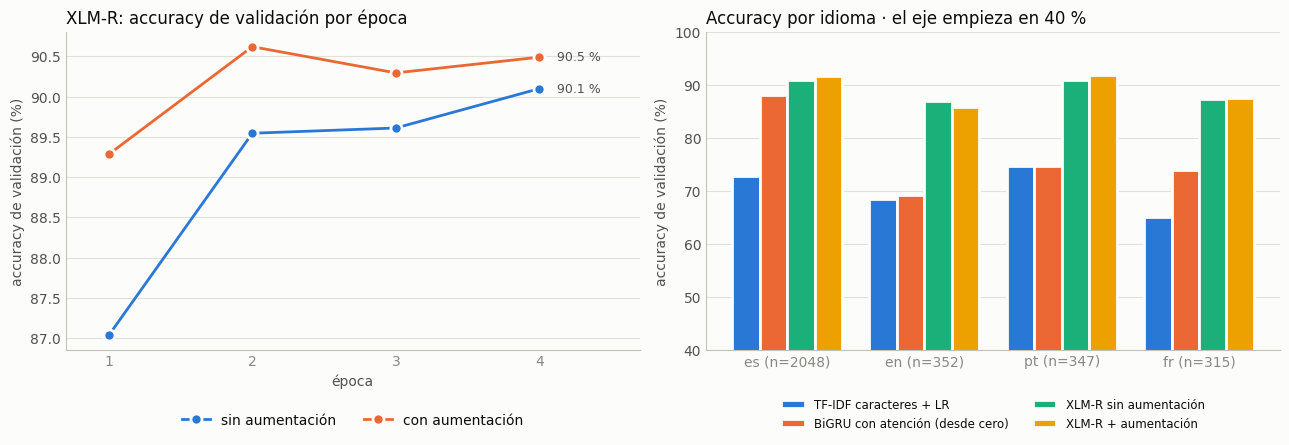

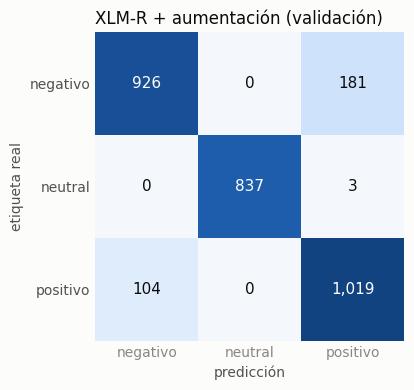

              precision    recall  f1-score   support

    negativo      0.899     0.836     0.867      1107
     neutral      1.000     0.996     0.998       840
    positivo      0.847     0.907     0.876      1123

    accuracy                          0.906      3070
   macro avg      0.915     0.913     0.914      3070
weighted avg      0.908     0.906     0.906      3070



In [14]:
# 7.3 Comparación: tabla, McNemar, curvas de aprendizaje y accuracy por idioma
resultados = tabla_resultados()
formatos = {c: '{:.4f}' for c in resultados.columns if c.startswith('acc') or c in ('accuracy', 'F1 macro')}
formatos.update({c: '{:.1f}' for c in resultados.columns if c == 'minutos'})
display(resultados.style.format(formatos, na_rep=''))
CON_AUG = 'XLM-R + aumentación' in P_VAL
if CON_AUG:
    p_sin, p_con = P_VAL['XLM-R sin aumentación'].argmax(1), P_VAL['XLM-R + aumentación'].argmax(1)
    mc_aug = mcnemar(p_con, p_sin, y_va)
    print(f"Con frente a sin aumentación: {100 * (accuracy_score(y_va, p_con) - accuracy_score(y_va, p_sin)):+.2f} pts | "
          f"McNemar: gana {mc_aug['gana']}, pierde {mc_aug['pierde']} (p = {mc_aug['p']:.3f})")
    for l in IDIOMAS:
        m = idioma_va == l
        if m.any():
            print(f'   {l:6s} (n={m.sum():4d}): sin {accuracy_score(y_va[m], p_sin[m]):.4f} → con {accuracy_score(y_va[m], p_con[m]):.4f}')

def tabla_robustez(nombres):
    """Accuracy de cada modelo sobre las versiones mezcladas de las reseñas de validación, por tipo de mezcla."""
    nombres = [n for n in nombres if n in P_AUG_VA]
    if not nombres:
        return None
    y_aug_va = aug_va.label.map(C2I).to_numpy()
    T = pd.DataFrame({n: pd.Series(P_AUG_VA[n].argmax(1) == y_aug_va).groupby(aug_va.tipo).mean() for n in nombres})
    T.loc['todas las sintéticas'] = [np.mean(P_AUG_VA[n].argmax(1) == y_aug_va) for n in nombres]
    T.loc['validación original'] = [accuracy_score(y_va, P_VAL[n].argmax(1)) for n in nombres]
    T.insert(0, 'reseñas', aug_va.tipo.value_counts().reindex(T.index).fillna(len(y_va)).astype(int))
    T.loc['todas las sintéticas', 'reseñas'] = len(aug_va)
    return T


ROBUSTEZ = tabla_robustez(list(P_AUG_VA))
if ROBUSTEZ is not None:
    print('\nRobustez: accuracy sobre versiones mezcladas de reseñas de VALIDACIÓN (ningún modelo las vio al entrenar):')
    display(ROBUSTEZ.style.format({c: '{:.4f}' for c in ROBUSTEZ.columns if c != 'reseñas'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
curvas = [('sin aumentación', hist_sin)] + ([('con aumentación', hist_con)] if CON_AUG else [])
finales = [100 * h['acc val'].iloc[-1] for _, h in curvas]
for k, ((nombre, h), color) in enumerate(zip(curvas, SERIES)):
    ax.plot(h['época'], 100 * h['acc val'], color=color, linewidth=2, marker='o', markersize=8,
            markeredgecolor=SUPERFICIE, markeredgewidth=2, label=nombre)
    separacion = 0.15 * (1 if k else -1) if len(finales) == 2 and abs(finales[0] - finales[1]) < 0.3 else 0.0
    ax.text(h['época'].iloc[-1] + 0.12, finales[k] + separacion, f'{finales[k]:.1f} %', va='center', fontsize=9, color=TINTA2)
ax.set_xlim(0.7, EPOCAS + 0.7)
ax.set_xticks(range(1, EPOCAS + 1)); ax.set_xlabel('época'); ax.set_ylabel('accuracy de validación (%)')
ax.yaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.set_title('XLM-R: accuracy de validación por época', color=TINTA)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)

ax = axes[1]
modelos_graf = [m for m in ['TF-IDF caracteres + LR', 'BiGRU con atención (desde cero)', 'XLM-R sin aumentación',
                            'XLM-R + aumentación'] if m in P_VAL]
idiomas_graf = [l for l in IDIOMAS if (idioma_va == l).sum() >= 20]
ancho = 0.8 / len(modelos_graf)
for k, (m, color) in enumerate(zip(modelos_graf, SERIES)):          # los valores exactos están en la tabla de arriba
    pred = P_VAL[m].argmax(1)
    vals = [100 * accuracy_score(y_va[idioma_va == l], pred[idioma_va == l]) for l in idiomas_graf]
    xs = np.arange(len(idiomas_graf)) + (k - (len(modelos_graf) - 1) / 2) * ancho
    ax.bar(xs, vals, width=ancho, color=color, edgecolor=SUPERFICIE, linewidth=2, label=m)
ax.set_xticks(range(len(idiomas_graf)), [f'{l} (n={(idioma_va == l).sum()})' for l in idiomas_graf])
ax.set_ylim(40, 100); ax.set_ylabel('accuracy de validación (%)')
ax.yaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.set_title('Accuracy por idioma · el eje empieza en 40 %', color=TINTA)
ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()

mejor_xlmr = max([m for m in ('XLM-R sin aumentación', 'XLM-R + aumentación') if m in P_VAL],
                 key=lambda m: accuracy_score(y_va, P_VAL[m].argmax(1)))
cm = confusion_matrix(y_va, P_VAL[mejor_xlmr].argmax(1))
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap=RAMPA_AZUL, vmin=0, vmax=cm.sum(1).max())
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=11,
                color='white' if cm[i, j] > 0.55 * cm.sum(1).max() else TINTA)
ax.set_xticks(range(3), CLASES); ax.set_yticks(range(3), CLASES); ax.tick_params(length=0)
ax.set_xlabel('predicción'); ax.set_ylabel('etiqueta real'); ax.set_title(f'{mejor_xlmr} (validación)', color=TINTA)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout(); plt.show()
print(classification_report(y_va, P_VAL[mejor_xlmr].argmax(1), target_names=CLASES, digits=3))

**Interpretación**
_(se completa con las cifras de la ejecución)_

### 7.4 Punto de partida ajustado a sentimiento: `clapAI/roberta-base-multilingual-sentiment`
**Qué es.**
- Es `xlm-roberta-base` ajustado por clapAI para clasificar sentimiento en negativo, neutral y positivo.
- Se entrenó con `clapAI/MultiLingualSentiment`: ≈3.1 M textos, sobre todo reseñas de productos y lugares, en 16 idiomas. Incluye ≈220 000 en español, ≈260 000 en francés, ≈50 000 en portugués y 1.5 M en inglés.
- Tanto el modelo como el dataset tienen licencia Apache-2.0.
- La arquitectura y el tokenizador son los mismos que los de XLM-R base.

**Cómo se usa.** Es **transferencia por tarea intermedia** (Phang et al., 2018, *STILTs*; Pruksachatkun et al., 2020, ACL): el modelo ya sabe reconocer la polaridad en los cuatro idiomas, y aquí se ajusta de nuevo a nuestra tarea.
- Se descarta su cabeza de clasificación y se pone la nuestra.
- La receta es la misma de 7.2: aumentación estática, épocas, tasas y semilla.

**Primero, sin ajustar.** Se mide cómo clasifica nuestra validación con su propia cabeza.
- Una prueba con 300 reseñas de train dio ≈35 %. El modelo llama *positivo* a casi todas nuestras neutrales, que son descripciones sin opinión ("llegó en tres días, lo uso a diario"), y *neutral* a muchas negativas.
- Su definición de las clases es otra. Por eso sus datos no se mezclan con train, y el modelo solo se usa como punto de partida.

In [15]:
# 7.4 XLM-R ajustado a sentimiento como punto de partida (misma receta que XLM-R + aumentación)
NOMBRE_SENT_0 = 'XLM-R-sent sin ajustar (su propia cabeza)'
NOMBRE_SENT = 'XLM-R-sent + aumentación' if CON_AUG else 'XLM-R-sent sin aumentación'
mejor_sent, hist_sent = None, None
if CORRER_SENT:
    if not SMOKE_TEST:
        t0 = time.time()
        registrar(NOMBRE_SENT_0, predecir_clasificador_publicado(MODELO_SENT, X_va), {'minutos': (time.time() - t0) / 60})
        print('Sin ajustar a nuestros datos (filas: etiqueta real; columnas: predicción):')
        display(pd.DataFrame(confusion_matrix(y_va, P_VAL[NOMBRE_SENT_0].argmax(1)), index=CLASES, columns=CLASES))
    X_s, y_s = (X_tr_aug, y_tr_aug) if CON_AUG else (X_tr, y_tr)
    t0 = time.time()
    modelo, mejor_sent, hist_sent = entrenar_transformer(X_s, y_s, X_va, y_va, etiqueta=NOMBRE_SENT, nombre=MODELO_SENT)
    registrar(NOMBRE_SENT, mejor_sent['P'],
              {'mejor época': mejor_sent['época'], 'reseñas de entrenamiento': len(X_s), 'minutos': (time.time() - t0) / 60})
    evaluar_extra(NOMBRE_SENT, modelo)
    del modelo
    liberar()
display(tabla_resultados().round(4))

config.json:   0%|          | 0.00/944 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  556MB            

... (3 outputs left out)

,negativo,neutral,positivo
negativo,282,488,337
neutral,18,82,740
positivo,69,400,654


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[XLM-R-sent + aumentación] 32,181 reseñas | 1006 pasos por época | 4 épocas
   época 1 paso 250/1006 pérdida 0.7169 (31 s)
   época 1 paso 500/1006 pérdida 0.5560 (63 s)
   época 1 paso 750/1006 pérdida 0.4878 (94 s)
   época 1 paso 1000/1006 pérdida 0.4480 (125 s)
[XLM-R-sent + aumentación] época 1: pérdida train 0.4473 | minutos 2.0920 | acc val 0.8886
   época 2 paso 250/1006 pérdida 0.3007 (31 s)
   época 2 paso 500/1006 pérdida 0.2986 (63 s)
   época 2 paso 750/1006 pérdida 0.2995 (94 s)
   época 2 paso 1000/1006 pérdida 0.2968 (125 s)
[XLM-R-sent + aumentación] época 2: pérdida train 0.2966 | minutos 2.1038 | acc val 0.9010
   época 3 paso 250/1006 pérdida 0.2630 (32 s)
   época 3 paso 500/1006 pérdida 0.2616 (63 s)
   época 3 paso 750/1006 pérdida 0.2610 (94 s)
   época 3 paso 1000/1006 pérdida 0.2594 (125 s)
[XLM-R-sent + aumentación] época 3: pérdida train 0.2591 | minutos 2.0925 | acc val 0.9091
   época 4 paso 250/1006 pérdida 0.2370 (31 s)
   época 4 paso 500/1006 pérdida 0

,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época,reseñas de entrenamiento
modelo,,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.500,0.7320,NaN,NaN
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.750,1.4595,6.0,NaN
XLM-R sin aumentación,0.9010,0.9088,0.9092,0.8693,0.9107,0.8730,0.875,4.9573,4.0,17396.0
XLM-R + aumentación,0.9062,0.9137,0.9175,0.8580,0.9193,0.8762,0.750,8.8186,2.0,32181.0
XLM-R-sent sin ajustar (su propia cabeza),0.3316,0.3103,0.3101,0.3324,0.4063,0.3873,0.375,0.2305,NaN,NaN
XLM-R-sent + aumentación,0.9091,0.9164,0.9209,0.8750,0.9193,0.8667,0.625,8.8513,3.0,32181.0


### 7.5 Cambio de idioma dinámico con regularización de consistencia
**Idea.** La aumentación de 7.2 añade un conjunto **fijo** de ≈15 000 sintéticas: cada una se ve 4 veces, siempre igual, y se trata como una reseña más. Aquí la misma aumentación se usa de otra forma.

**Cómo funciona.** Cada reseña de entrenamiento viaja con una **versión mezclada**, construida con los diccionarios de MUSE y la función `mezclar_idiomas` de la sección 6:
1. **La versión mezclada es nueva en cada época.** El español, el portugués y el francés reciben tramos en inglés; el inglés, en español, portugués o francés, al azar. Es la aumentación **dinámica** de CoSDA-ML (Qin et al., 2020, IJCAI): en 4 épocas el modelo ve 4 mezclas distintas de cada reseña.
2. **La pérdida tiene dos partes:**
   - la entropía cruzada de la reseña y de su versión mezclada (promediadas);
   - λ · **KL simétrica** entre las dos distribuciones predichas, con `LAMBDA_CONS` = 1.
3. **El segundo término es la regularización de consistencia** de xTune (Zheng et al., 2021, ACL), que también cambia palabras con los diccionarios de MUSE. Con *dropout* activo, también incluye el efecto de R-Drop (Liang et al., 2021, NeurIPS). Pide que la predicción **no cambie** al cambiar de idioma partes de la reseña, que es exactamente lo que no cambia su etiqueta.

**Datos, coste y punto de partida.**
- **Datos:** el entrenamiento usa solo las reseñas de entrenamiento de la partición; no se usan las sintéticas fijas. La versión mezclada de una reseña de validación nunca se genera.
- **Coste:** cada paso procesa 32 reseñas y sus 32 versiones mezcladas, un coste parecido al de 7.2.
- **Punto de partida:** el mejor de 7.2 y 7.4 en validación.

In [16]:
# 7.5 Cambio de idioma dinámico con consistencia, desde el mejor punto de partida de 7.2 / 7.4
acc_x = accuracy_score(y_va, P_VAL[mejor_xlmr].argmax(1))
INIT_CONS = MODELO_SENT if mejor_sent is not None and mejor_sent['acc'] > acc_x else MODELO
NOMBRE_CONS = f'{CORTO[INIT_CONS]} + consistencia'
mejor_cons, hist_cons = None, None
if CORRER_CONSISTENCIA and CORRER_AUMENTACION:
    print(f'Punto de partida: {INIT_CONS}')
    ejemplo = tr[tr.idioma == 'en'].iloc[0]
    print(f'\nVersiones mezcladas de una misma reseña en las épocas 1-3 [{ejemplo.label}]:\n   original: {ejemplo.text[:220]}')
    for ep in (1, 2, 3):
        rng_ej = np.random.default_rng([SEED, ep, 0])
        destino = IDIOMA_DESTINO['en'][int(rng_ej.integers(3))]
        print(f'   época {ep} (en+{destino}): {(mezclar_idiomas(ejemplo.text, DICCIONARIOS[("en", destino)], rng_ej) or "")[:220]}')
    print()
    t0 = time.time()
    modelo, mejor_cons, hist_cons = entrenar_transformer(X_tr, y_tr, X_va, y_va, etiqueta=NOMBRE_CONS, nombre=INIT_CONS,
                                                         idiomas=tr.idioma.to_numpy())
    registrar(NOMBRE_CONS, mejor_cons['P'],
              {'mejor época': mejor_cons['época'], 'reseñas de entrenamiento': len(X_tr), 'minutos': (time.time() - t0) / 60})
    evaluar_extra(NOMBRE_CONS, modelo)
    del modelo
    liberar()
display(tabla_resultados().round(4))

Punto de partida: clapAI/roberta-base-multilingual-sentiment

Versiones mezcladas de una misma reseña en las épocas 1-3 [neutral]:
   original: I bought this for a relative a couple of weeks ago, kind of spontaneously during a visit I paid them. They told me the device charges through a USB type C port, so no batteries or anything weird needed. It also works plu
   época 1 (en+pt): I bought this for a relative a couple of weeks ago, kind of spontaneously during a visit I pagas eles. Elas contada me os aparelho encargos through a USB type C port, so no pilhas or anything weird needed. It also works 
   época 2 (en+es): I comprado este para a relativa a pareja of weeks ago, amable of espontáneamente durante a visitar I paid ellas. Ellas contada me the dispositivos cargas through a USB type C puerto, so no batteries or anything extraño n
   época 3 (en+fr): I achetées cet pour a parent a couple of semaines ago, aimable of spontanément durant a visite I rémunéré eux. Ils racontée me the de

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[XLM-R-sent + consistencia] 17,396 reseñas (+ una versión mezclada nueva de cada una por época) | 544 pasos por época | 4 épocas
   época 1 paso 250/544 pérdida 0.6973 (53 s)
   época 1 paso 500/544 pérdida 0.5497 (106 s)
[XLM-R-sent + consistencia] época 1: pérdida train 0.5341 | minutos 1.9162 | acc val 0.8863
   época 2 paso 250/544 pérdida 0.3479 (53 s)
   época 2 paso 500/544 pérdida 0.3414 (106 s)
[XLM-R-sent + consistencia] época 2: pérdida train 0.3409 | minutos 1.9173 | acc val 0.9065
   época 3 paso 250/544 pérdida 0.3207 (53 s)
   época 3 paso 500/544 pérdida 0.3146 (105 s)
[XLM-R-sent + consistencia] época 3: pérdida train 0.3150 | minutos 1.9119 | acc val 0.9036
   época 4 paso 250/544 pérdida 0.3030 (53 s)
   época 4 paso 500/544 pérdida 0.2976 (106 s)
[XLM-R-sent + consistencia] época 4: pérdida train 0.2975 | minutos 1.9143 | acc val 0.9039


,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época,reseñas de entrenamiento
modelo,,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.500,0.7320,NaN,NaN
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.750,1.4595,6.0,NaN
XLM-R sin aumentación,0.9010,0.9088,0.9092,0.8693,0.9107,0.8730,0.875,4.9573,4.0,17396.0
XLM-R + aumentación,0.9062,0.9137,0.9175,0.8580,0.9193,0.8762,0.750,8.8186,2.0,32181.0
XLM-R-sent sin ajustar (su propia cabeza),0.3316,0.3103,0.3101,0.3324,0.4063,0.3873,0.375,0.2305,NaN,NaN
XLM-R-sent + aumentación,0.9091,0.9164,0.9209,0.8750,0.9193,0.8667,0.625,8.8513,3.0,32181.0
XLM-R-sent + consistencia,0.9065,0.9130,0.9121,0.8977,0.9222,0.8667,0.750,8.0496,2.0,17396.0


## 8. Ensamble de las variantes, configuración final y mezcla con la línea base
**Ensamble.** Es el promedio de las probabilidades de todas las variantes de XLM-R entrenadas en la sección 7, con **pesos iguales**:
- sin aumentación;
- con aumentación;
- desde el XLM-R ajustado a sentimiento;
- con consistencia.

Los pesos no se ajustan, para no adaptar nada a la validación. Promediar modelos que aciertan lo mismo pero se equivocan en reseñas distintas corrige parte de esos errores y reduce la varianza entre ejecuciones (ver la iteración 4 en la portada).

**Tres decisiones**, sobre la misma validación:
1. **Modelo.** Los candidatos son:
   - la mejor variante de XLM-R de 7.1/7.2 (la receta de la iteración 2);
   - el XLM-R ajustado a sentimiento (7.4);
   - el entrenamiento con consistencia (7.5);
   - el ensamble.

   Gana el de mayor accuracy, pero dejar la receta de la iteración 2 exige mejorarla en al menos **0.2 puntos** (`GANANCIA_MINIMA`). La tabla incluye la prueba de McNemar frente a esa receta y la robustez a las mezclas de idiomas. Otra tabla muestra en cuántas reseñas difieren las variantes: eso es lo que el ensamble puede aprovechar.
2. **Mezcla con la línea base:** `P = (1 − w)·P_modelo + w·P_TF-IDF`, con `w` entre 0 y 0.5 y el mismo umbral de 0.2 puntos.
3. **Configuración de cada miembro:**
   - **Si gana el ensamble:** cada variante se reentrena con el 100 % de train, con su punto de partida, su tipo de entrenamiento y su mejor época (`SEMILLAS_ENSAMBLE`).
   - **Si gana una variante sola:** esa variante con `SEMILLAS_FINAL`.

In [17]:
P_x = P_VAL[mejor_xlmr]
VARIANTES = [n for n in ('XLM-R sin aumentación', 'XLM-R + aumentación', NOMBRE_SENT, NOMBRE_CONS) if n in P_VAL]
NOMBRE_ENS = f'Ensamble de {len(VARIANTES)} variantes de XLM-R'
if len(VARIANTES) > 1:
    registrar(NOMBRE_ENS, np.mean([P_VAL[n] for n in VARIANTES], axis=0))
    if all(n in P_AUG_VA for n in VARIANTES):
        P_AUG_VA[NOMBRE_ENS] = np.mean([P_AUG_VA[n] for n in VARIANTES], axis=0)
    pred_var = {n: P_VAL[n].argmax(1) for n in VARIANTES}
    DESACUERDOS = pd.DataFrame([[int((pred_var[a] != pred_var[b]).sum()) for b in VARIANTES] for a in VARIANTES],
                               index=VARIANTES, columns=VARIANTES)
    print(f'Reseñas de validación (de {len(y_va):,}) en que cada par de variantes predice distinto:')
    display(DESACUERDOS)
CANDIDATOS = [n for n in dict.fromkeys((mejor_xlmr, NOMBRE_SENT, NOMBRE_CONS, NOMBRE_ENS)) if n in P_VAL]
acc_cand = {n: accuracy_score(y_va, P_VAL[n].argmax(1)) for n in CANDIDATOS}
mejor_cand = max(CANDIDATOS, key=acc_cand.get)
nombre_base = mejor_cand if acc_cand[mejor_cand] - acc_cand[mejor_xlmr] >= GANANCIA_MINIMA else mejor_xlmr

columnas = ['accuracy', 'F1 macro'] + [c for c in tabla_resultados().columns if c.startswith('acc ')]
comparacion = tabla_resultados().loc[CANDIDATOS, columnas]
comparacion.insert(1, 'frente a iteración 2 (pts)', 100 * (comparacion.accuracy - acc_cand[mejor_xlmr]))
MCNEMAR_CAND = {n: mcnemar(P_VAL[n].argmax(1), P_x.argmax(1), y_va) for n in CANDIDATOS if n != mejor_xlmr}
comparacion['gana / pierde'] = ['' if n == mejor_xlmr else f"{MCNEMAR_CAND[n]['gana']} / {MCNEMAR_CAND[n]['pierde']}"
                                for n in CANDIDATOS]
comparacion['p McNemar'] = [np.nan if n == mejor_xlmr else MCNEMAR_CAND[n]['p'] for n in CANDIDATOS]
formatos = {c: '{:.4f}' for c in columnas}
formatos.update({'frente a iteración 2 (pts)': '{:+.2f}', 'p McNemar': '{:.3f}'})
print(f'\nCandidatos (gana / pierde: reseñas que acierta el candidato y falla {mejor_xlmr}, y al revés):')
display(comparacion.style.format(formatos, na_rep=''))
ROBUSTEZ_CAND = tabla_robustez(CANDIDATOS) if len(CANDIDATOS) > 1 else None
if ROBUSTEZ_CAND is not None:
    print('\nRobustez a mezclas de idiomas (versiones mezcladas de las reseñas de validación):')
    display(ROBUSTEZ_CAND.style.format({c: '{:.4f}' for c in ROBUSTEZ_CAND.columns if c != 'reseñas'}))
conf_x = P_x.max(1)
for nombre_banda, m in [('confianza < 0.7', conf_x < 0.7), ('confianza 0.7-0.97', (conf_x >= 0.7) & (conf_x < 0.97)),
                        ('confianza ≥ 0.97', conf_x >= 0.97)]:
    print(f'   {nombre_banda:20s} (n={m.sum():4d}): {mejor_xlmr} {accuracy_score(y_va[m], P_x[m].argmax(1)):.3f} → '
          f'{nombre_base} {accuracy_score(y_va[m], P_VAL[nombre_base][m].argmax(1)):.3f}')
print(f'\nModelo elegido: {nombre_base} ({100 * (acc_cand[nombre_base] - acc_cand[mejor_xlmr]):+.2f} pts frente a '
      f'{mejor_xlmr}; el umbral para cambiar es +{100 * GANANCIA_MINIMA:.1f})')

# Mezcla con TF-IDF sobre el modelo elegido
P_base = P_VAL[nombre_base]
ws = np.round(np.arange(0, 0.51, 0.05), 2)
acc_w = np.array([accuracy_score(y_va, ((1 - w) * P_base + w * P_tfidf_va).argmax(1)) for w in ws])
print('\naccuracy de validación según el peso de TF-IDF en la mezcla:')
print('   ' + ' | '.join(f'w={w:.2f}: {a:.4f}' for w, a in zip(ws, acc_w)))
w_mejor = float(ws[acc_w.argmax()])
PESO_TFIDF = w_mejor if acc_w.max() - acc_w[0] >= GANANCIA_MINIMA else 0.0
if PESO_TFIDF > 0:
    registrar(f'{nombre_base} + TF-IDF (w={PESO_TFIDF})', (1 - PESO_TFIDF) * P_base + PESO_TFIDF * P_tfidf_va)

# Configuración de cada variante: (punto de partida, entrenamiento, épocas)
CONFIGURACIONES = {'XLM-R sin aumentación': (MODELO, 'sin aumentación', mejor_sin['época'])}
if CON_AUG:
    CONFIGURACIONES['XLM-R + aumentación'] = (MODELO, 'aumentación estática', mejor_con['época'])
if mejor_sent is not None:
    CONFIGURACIONES[NOMBRE_SENT] = (MODELO_SENT, 'aumentación estática' if CON_AUG else 'sin aumentación', mejor_sent['época'])
if mejor_cons is not None:
    CONFIGURACIONES[NOMBRE_CONS] = (INIT_CONS, 'consistencia', mejor_cons['época'])
# Miembros del modelo final: (variante, punto de partida, entrenamiento, épocas, semilla)
if nombre_base == NOMBRE_ENS:
    MIEMBROS_FINAL = [(v, *CONFIGURACIONES[v], s) for v in VARIANTES for s in SEMILLAS_ENSAMBLE]
else:
    MIEMBROS_FINAL = [(nombre_base, *CONFIGURACIONES[nombre_base], s) for s in SEMILLAS_FINAL]
print(f'\nConfiguración final: {nombre_base} | {len(MIEMBROS_FINAL)} miembros | peso TF-IDF: {PESO_TFIDF} '
      f'(mejor w = {w_mejor}, {100 * (acc_w.max() - acc_w[0]):+.2f} pts frente a w = 0)')
for v, ini, ent, ep, s in MIEMBROS_FINAL:
    print(f'   {v:28s} | punto de partida: {ini:44s} | entrenamiento: {ent:20s} | épocas: {ep} | semilla {s}')
display(tabla_resultados().round(4))

Reseñas de validación (de 3,070) en que cada par de variantes predice distinto:


,XLM-R sin aumentación,XLM-R + aumentación,XLM-R-sent + aumentación,XLM-R-sent + consistencia
XLM-R sin aumentación,0,175,232,226
XLM-R + aumentación,175,0,249,221
XLM-R-sent + aumentación,232,249,0,222
XLM-R-sent + consistencia,226,221,222,0



Candidatos (gana / pierde: reseñas que acierta el candidato y falla XLM-R + aumentación, y al revés):


,accuracy,frente a iteración 2 (pts),F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,gana / pierde,p McNemar
modelo,,,,,,,,,,
XLM-R + aumentación,0.9062,+0.00,0.9137,0.9175,0.8580,0.9193,0.8762,0.7500,,
XLM-R-sent + aumentación,0.9091,+0.29,0.9164,0.9209,0.8750,0.9193,0.8667,0.6250,129 / 120,0.612
XLM-R-sent + consistencia,0.9065,+0.03,0.9130,0.9121,0.8977,0.9222,0.8667,0.7500,111 / 110,1.000
Ensamble de 4 variantes de XLM-R,0.9111,+0.49,0.9181,0.9194,0.8750,0.9308,0.8794,0.7500,95 / 80,0.290



Robustez a mezclas de idiomas (versiones mezcladas de las reseñas de validación):


,reseñas,XLM-R + aumentación,XLM-R-sent + aumentación,XLM-R-sent + consistencia,Ensamble de 4 variantes de XLM-R
tipo,,,,,
en→en+es,352,0.8438,0.8722,0.8835,0.8835
en→en+fr,352,0.8438,0.8693,0.8977,0.8750
en→en+pt,352,0.8665,0.8636,0.8807,0.8580
es→es+en,962,0.9241,0.9262,0.9179,0.9252
fr→fr+en,313,0.8722,0.8690,0.8626,0.8754
pt→pt+en,347,0.9135,0.9193,0.9164,0.9135
todas las sintéticas,2678,0.8880,0.8958,0.8992,0.8969
validación original,3070,0.9062,0.9091,0.9065,0.9111


   confianza < 0.7      (n= 508): XLM-R + aumentación 0.575 → Ensamble de 4 variantes de XLM-R 0.593
   confianza 0.7-0.97   (n=1350): XLM-R + aumentación 0.947 → Ensamble de 4 variantes de XLM-R 0.951
   confianza ≥ 0.97     (n=1212): XLM-R + aumentación 1.000 → Ensamble de 4 variantes de XLM-R 1.000

Modelo elegido: Ensamble de 4 variantes de XLM-R (+0.49 pts frente a XLM-R + aumentación; el umbral para cambiar es +0.2)

accuracy de validación según el peso de TF-IDF en la mezcla:
   w=0.00: 0.9111 | w=0.05: 0.9127 | w=0.10: 0.9134 | w=0.15: 0.9140 | w=0.20: 0.9143 | w=0.25: 0.9121 | w=0.30: 0.9117 | w=0.35: 0.9134 | w=0.40: 0.9117 | w=0.45: 0.9101 | w=0.50: 0.9072

Configuración final: Ensamble de 4 variantes de XLM-R | 4 miembros | peso TF-IDF: 0.2 (mejor w = 0.2, +0.33 pts frente a w = 0)
   XLM-R sin aumentación        | punto de partida: xlm-roberta-base                             | entrenamiento: sin aumentación      | épocas: 4 | semilla 42
   XLM-R + aumentación          | p

,accuracy,F1 macro,acc es,acc en,acc pt,acc fr,acc es+en,minutos,mejor época,reseñas de entrenamiento
modelo,,,,,,,,,,
TF-IDF caracteres + LR,0.7166,0.7374,0.7280,0.6847,0.7464,0.6508,0.500,0.7320,NaN,NaN
BiGRU con atención (desde cero),0.8293,0.8424,0.8809,0.6932,0.7464,0.7397,0.750,1.4595,6.0,NaN
XLM-R sin aumentación,0.9010,0.9088,0.9092,0.8693,0.9107,0.8730,0.875,4.9573,4.0,17396.0
XLM-R + aumentación,0.9062,0.9137,0.9175,0.8580,0.9193,0.8762,0.750,8.8186,2.0,32181.0
XLM-R-sent sin ajustar (su propia cabeza),0.3316,0.3103,0.3101,0.3324,0.4063,0.3873,0.375,0.2305,NaN,NaN
XLM-R-sent + aumentación,0.9091,0.9164,0.9209,0.8750,0.9193,0.8667,0.625,8.8513,3.0,32181.0
XLM-R-sent + consistencia,0.9065,0.9130,0.9121,0.8977,0.9222,0.8667,0.750,8.0496,2.0,17396.0
Ensamble de 4 variantes de XLM-R,0.9111,0.9181,0.9194,0.8750,0.9308,0.8794,0.750,NaN,NaN,NaN
Ensamble de 4 variantes de XLM-R + TF-IDF (w=0.2),0.9143,0.9212,0.9209,0.8778,0.9424,0.8857,0.750,NaN,NaN,NaN


## 9. Modelo final: 100 % de train, predicción de eval y guardado
El modelo final usa la configuración elegida en la sección 8. Cada miembro se entrena con **las 20 466 reseñas de train**, según su tipo de entrenamiento:
- **Sin aumentación:** solo esas reseñas.
- **Aumentación estática:** más todas las sintéticas de la sección 6.
- **Consistencia:** con una versión mezclada nueva de cada reseña en cada época.

Cada miembro se entrena el número de épocas de su mejor época en validación, sin validación. Las probabilidades se promedian primero entre semillas de cada variante y después entre variantes, con pesos iguales. **Aquí, y solo aquí, se usa `eval.csv`, únicamente para predecir.**

In [18]:
def guardar_modelo(modelo, carpeta, extra=None):
    carpeta.mkdir(parents=True, exist_ok=True)
    modelo.backbone.save_pretrained(carpeta / 'backbone')
    modelo.tok.save_pretrained(carpeta / 'backbone')
    torch.save(modelo.cabeza.state_dict(), carpeta / 'cabeza.pt')
    (carpeta / 'config_clasificador.json').write_text(json.dumps(
        {'modelo_base': modelo.nombre, 'max_len': MAX_LEN, 'representacion': 'concat(token inicial, media)',
         'clases': CLASES, 'dropout': DROPOUT, **(extra or {})}, indent=1, ensure_ascii=False))


def cargar_modelo(carpeta):
    """Reconstruye un clasificador guardado: backbone y tokenizador de transformers + cabeza lineal."""
    cfg = json.loads((carpeta / 'config_clasificador.json').read_text())
    modelo = ClasificadorTransformer(cfg['modelo_base'], dropout=cfg['dropout'],
                                     backbone=AutoModel.from_pretrained(carpeta / 'backbone', dtype=torch.float32),
                                     tok=AutoTokenizer.from_pretrained(carpeta / 'backbone'))
    modelo.cabeza.load_state_dict(torch.load(carpeta / 'cabeza.pt', map_location='cpu'))
    return modelo.to(DEVICE).eval()


def promedio(por_variante):
    """Promedia las probabilidades primero entre semillas de cada variante y después entre variantes (pesos iguales)."""
    return np.mean([np.mean(v, axis=0) for v in por_variante.values()], axis=0)


def carpeta_de(variante, semilla):
    """Nombre de carpeta de un miembro: 'XLM-R + aumentación', 42 → 'xlm_r_con_aumentacion_semilla_42'."""
    return re.sub(r'[^a-z0-9]+', '_', _sin_tildes(variante.replace('+', ' con '))).strip('_') + f'_semilla_{semilla}'


DIR_MODELO = DIR_SALIDA / f'modelo_final{SUFIJO}'
EJEMPLOS = ['La batería es excelente, pero la cámara resultó decepcionante.',
            'The camera was disappointing. Still, the battery is excellent.',
            'A entrega chegou em três dias e veio com duas pilhas AA.',
            'Le son est correct, mais honnêtement je regrette cet achat.',
            'La silla llegó rápido and the assembly was easy, pero the armrests are too hard.']
if ENTRENAR_FINAL:
    X_base, y_base = train.text.to_numpy(), train.label.map(C2I).to_numpy()
    X_aug_full = np.concatenate([X_base, AUG.text.to_numpy()])
    y_aug_full = np.concatenate([y_base, AUG.label.map(C2I).to_numpy()])
    textos_eval = evaluacion.text.to_numpy()
    t0 = time.time()
    P_EVAL_MIEMBROS, P_EJ_MIEMBROS, HIST_FINAL = collections.defaultdict(list), collections.defaultdict(list), {}
    for k, (variante, nombre, entrenamiento, ep, s) in enumerate(MIEMBROS_FINAL):
        if entrenamiento == 'aumentación estática':
            X_m, y_m, idiomas_m = X_aug_full, y_aug_full, None
        else:
            X_m, y_m = X_base, y_base
            idiomas_m = train.idioma.to_numpy() if entrenamiento == 'consistencia' else None
        etiqueta = f'final {k + 1}/{len(MIEMBROS_FINAL)}: {variante}, semilla {s}'
        modelo_final, _, HIST_FINAL[etiqueta] = entrenar_transformer(X_m, y_m, epocas=ep, semilla=s, etiqueta=etiqueta,
                                                                     nombre=nombre, idiomas=idiomas_m)
        P_EVAL_MIEMBROS[variante].append(predecir_transformer(modelo_final, textos_eval))
        P_EJ_MIEMBROS[variante].append(predecir_transformer(modelo_final, EJEMPLOS))
        CARPETA_ULTIMO = DIR_MODELO / carpeta_de(variante, s)
        guardar_modelo(modelo_final, CARPETA_ULTIMO, {'variante': variante, 'semilla': s, 'epocas': int(ep),
                                                      'entrenamiento': entrenamiento})
        if k < len(MIEMBROS_FINAL) - 1:
            del modelo_final
            liberar()
    P_eval_tr, P_ej = promedio(P_EVAL_MIEMBROS), promedio(P_EJ_MIEMBROS)
    if PESO_TFIDF > 0:
        tfidf_final = clone(tfidf_lr).fit(X_base, y_base)
        joblib.dump(tfidf_final, DIR_MODELO / 'tfidf_lr.joblib')
        P_eval = (1 - PESO_TFIDF) * P_eval_tr + PESO_TFIDF * tfidf_final.predict_proba(textos_eval)
        P_ej = (1 - PESO_TFIDF) * P_ej + PESO_TFIDF * tfidf_final.predict_proba(EJEMPLOS)
    else:
        P_eval = P_eval_tr
    (DIR_MODELO / 'mezcla.json').write_text(json.dumps(
        {'configuracion': nombre_base,
         'miembros': [{'variante': v, 'carpeta': carpeta_de(v, s), 'punto_de_partida': ini, 'entrenamiento': ent,
                       'epocas': int(ep), 'semilla': s} for v, ini, ent, ep, s in MIEMBROS_FINAL],
         'lambda_consistencia': LAMBDA_CONS,
         'promedio': 'primero entre semillas de cada variante y después entre variantes (pesos iguales)',
         'peso_tfidf': PESO_TFIDF, 'aumentacion_tipo': 'cambio de idioma con diccionarios MUSE'},
        ensure_ascii=False, indent=1))
    MINUTOS_FINAL = (time.time() - t0) / 60
    print(f'Modelo final entrenado y eval predicho en {MINUTOS_FINAL:.1f} min')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[final 1/4: XLM-R sin aumentación, semilla 42] 20,466 reseñas | 640 pasos por época | 4 épocas
   época 1 paso 250/640 pérdida 0.7791 (31 s)
   época 1 paso 500/640 pérdida 0.5886 (62 s)
[final 1/4: XLM-R sin aumentación, semilla 42] época 1: pérdida train 0.5375 | minutos 1.3135
   época 2 paso 250/640 pérdida 0.3333 (31 s)
   época 2 paso 500/640 pérdida 0.3280 (61 s)
[final 1/4: XLM-R sin aumentación, semilla 42] época 2: pérdida train 0.3255 | minutos 1.3117
   época 3 paso 250/640 pérdida 0.3008 (31 s)
   época 3 paso 500/640 pérdida 0.2943 (62 s)
[final 1/4: XLM-R sin aumentación, semilla 42] época 3: pérdida train 0.2948 | minutos 1.3144
   época 4 paso 250/640 pérdida 0.2815 (31 s)
   época 4 paso 500/640 pérdida 0.2790 (62 s)
[final 1/4: XLM-R sin aumentación, semilla 42] época 4: pérdida train 0.2767 | minutos 1.3148


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[final 2/4: XLM-R + aumentación, semilla 42] 37,929 reseñas | 1186 pasos por época | 2 épocas
   época 1 paso 250/1186 pérdida 0.7847 (31 s)
   época 1 paso 500/1186 pérdida 0.6075 (63 s)
   época 1 paso 750/1186 pérdida 0.5300 (94 s)
   época 1 paso 1000/1186 pérdida 0.4870 (125 s)
[final 2/4: XLM-R + aumentación, semilla 42] época 1: pérdida train 0.4642 | minutos 2.4658
   época 2 paso 250/1186 pérdida 0.3164 (31 s)
   época 2 paso 500/1186 pérdida 0.3126 (62 s)
   época 2 paso 750/1186 pérdida 0.3093 (94 s)
   época 2 paso 1000/1186 pérdida 0.3064 (125 s)
[final 2/4: XLM-R + aumentación, semilla 42] época 2: pérdida train 0.3053 | minutos 2.4637


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[final 4/4: XLM-R-sent + consistencia, semilla 42] 20,466 reseñas (+ una versión mezclada nueva de cada una por época) | 640 pasos por época | 2 épocas
   época 1 paso 250/640 pérdida 0.6394 (53 s)
   época 1 paso 500/640 pérdida 0.5146 (106 s)
[final 4/4: XLM-R-sent + consistencia, semilla 42] época 1: pérdida train 0.4838 | minutos 2.2541
   época 2 paso 250/640 pérdida 0.3400 (53 s)
   época 2 paso 500/640 pérdida 0.3361 (105 s)
[final 4/4: XLM-R-sent + consistencia, semilla 42] época 2: pérdida train 0.3357 | minutos 2.2486


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo final entrenado y eval predicho en 24.1 min


In [19]:
if ENTRENAR_FINAL:
    submission = pd.DataFrame({'id': evaluacion.id, 'answer': np.array(CLASES)[P_eval.argmax(1)]})
    assert list(submission.columns) == list(muestra.columns) == ['id', 'answer']
    assert len(submission) == len(muestra) and (submission.id.values == muestra.id.values).all()
    assert submission.answer.isin(CLASES).all()
    RUTA_SUB = DIR_SALIDA / f'submission_parte2{SUFIJO}.csv'
    submission.to_csv(RUTA_SUB, index=False)
    print(f'{RUTA_SUB} generado: {submission.shape}')
    display(pd.DataFrame({'eval (predicho)': submission.answer.value_counts(normalize=True),
                          'train (real)': train.label.value_counts(normalize=True)}).round(3))

    # Comprobación: el último modelo guardado, recargado, reproduce sus predicciones en las primeras reseñas de eval
    recargado = cargar_modelo(CARPETA_ULTIMO)
    P_a = predecir_transformer(modelo_final, textos_eval[:64])
    P_b = predecir_transformer(recargado, textos_eval[:64])
    print(f'Modelo recargado ({CARPETA_ULTIMO.name}) reproduce las predicciones:', bool((P_a.argmax(1) == P_b.argmax(1)).all()),
          f'| diferencia máxima de probabilidad {np.abs(P_a - P_b).max():.1e}')
    print('\nModelo final en reseñas de ejemplo:')
    for t, p in zip(EJEMPLOS, P_ej):
        print(f'   {CLASES[p.argmax()]:9s} {p.round(2)}  {t}')
    del recargado
    liberar()

/content/parte2_salida_v2/submission_parte2_v5.csv generado: (6781, 2)


,eval (predicho),train (real)
positivo,0.424,0.366
negativo,0.385,0.361
neutral,0.191,0.274


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo recargado (xlm_r_sent_con_consistencia_semilla_42) reproduce las predicciones: True | diferencia máxima de probabilidad 0.0e+00

Modelo final en reseñas de ejemplo:
   negativo  [0.91 0.01 0.07]  La batería es excelente, pero la cámara resultó decepcionante.
   positivo  [0.2  0.01 0.79]  The camera was disappointing. Still, the battery is excellent.
   neutral   [0.01 0.98 0.01]  A entrega chegou em três dias e veio com duas pilhas AA.
   negativo  [0.86 0.01 0.13]  Le son est correct, mais honnêtement je regrette cet achat.
   negativo  [0.86 0.01 0.13]  La silla llegó rápido and the assembly was easy, pero the armrests are too hard.


In [20]:
# Archivos para el análisis de errores (validación) y las probabilidades de eval
analisis = va[['id', 'label', 'idioma', 'tokens']].copy()
for nombre, P in P_VAL.items():
    for j, c in enumerate(CLASES):
        analisis[f'{nombre} | {c}'] = P[:, j].round(5)
analisis.to_csv(DIR_SALIDA / f'probabilidades_validacion{SUFIJO}.csv', index=False)
if P_AUG_VA:
    rob = aug_va[['origen_id', 'tipo', 'label']].copy()
    for nombre, P in P_AUG_VA.items():
        rob[f'{nombre} | pred'] = np.array(CLASES)[P.argmax(1)]
    rob.to_csv(DIR_SALIDA / f'predicciones_sinteticas_validacion{SUFIJO}.csv', index=False)
if ENTRENAR_FINAL:
    prob_eval = pd.DataFrame({'id': evaluacion.id, **{c: P_eval[:, j].round(5) for j, c in enumerate(CLASES)}})
    for variante, lista in P_EVAL_MIEMBROS.items():        # también cada miembro por separado
        semillas_v = [s for v, *_, s in MIEMBROS_FINAL if v == variante]
        for s, P_s in zip(semillas_v, lista):
            for j, c in enumerate(CLASES):
                prob_eval[f'{variante} · semilla {s} | {c}'] = P_s[:, j].round(5)
    prob_eval.to_csv(DIR_SALIDA / f'probabilidades_eval{SUFIJO}.csv', index=False)
print('Archivos en', DIR_SALIDA.resolve(), ':', sorted(p.name for p in DIR_SALIDA.iterdir()))
if EN_COLAB and ENTRENAR_FINAL:
    from google.colab import files
    for nombre in [f'submission_parte2{SUFIJO}.csv', f'probabilidades_validacion{SUFIJO}.csv']:
        files.download(str(DIR_SALIDA / nombre))
    if DESCARGAR_MODELO:
        files.download(shutil.make_archive(str(DIR_MODELO), 'zip', DIR_MODELO))

Archivos en /content/parte2_salida_v2 : ['aumentacion_diccionarios.csv', 'diccionarios', 'modelo_final_v5', 'predicciones_sinteticas_validacion_v5.csv', 'probabilidades_eval_v5.csv', 'probabilidades_validacion_v5.csv', 'submission_parte2_v5.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Cómo cargar el modelo en otra sesión.** Hay que ejecutar las celdas de configuración (secciones 1-2) y la de definiciones de la sección 7 (`ClasificadorTransformer`). Después, para cada miembro listado en `modelo_final_v5/mezcla.json`:
```python
miembros = json.loads((DIR_SALIDA_DRIVE / 'modelo_final_v5' / 'mezcla.json').read_text())['miembros']
P = np.mean([predecir_transformer(cargar_modelo(DIR_SALIDA_DRIVE / 'modelo_final_v5' / m['carpeta']), ['texto de una reseña'])
             for m in miembros], axis=0)
```
Con una semilla por variante, ese promedio simple es el de la sección 9. Con varias, hay que promediar primero dentro de cada variante.

La carpeta `modelo_final_v5/` está en la subcarpeta `parte2_salida_v2` de la carpeta de Drive (o en `DIR_SALIDA` sin Drive). Contiene:
- por miembro: `backbone/` (pesos y tokenizador de `transformers`), `cabeza.pt` (capa de clasificación) y `config_clasificador.json`;
- `mezcla.json`: miembros (variante, punto de partida, entrenamiento, épocas y semilla), forma de promediar y peso de TF-IDF, con `tfidf_lr.joblib` si se usa.

## 10. Resumen numérico y copia de las salidas a Drive

In [21]:
ROBUSTEZ_TODO = tabla_robustez(list(P_AUG_VA))
RESUMEN = {
    'versiones': {'torch': torch.__version__, 'transformers': transformers.__version__, 'sklearn': sklearn.__version__},
    'gpu': {'nombre': GPU_NOMBRE, 'gb': round(GPU_GB, 1), 'precision': str(DTYPE_AMP), 'grad_scaler': USA_SCALER,
            'batch_pred': BATCH_PRED},
    'smoke_test': SMOKE_TEST,
    'config': {'modelo': MODELO, 'modelo_sentimiento': MODELO_SENT if CORRER_SENT else None,
               'perfiles': {m: PERFILES[m] for m in (MODELO, MODELO_SENT)}, 'max_len': MAX_LEN, 'epocas': EPOCAS,
               'warmup': WARMUP, 'dropout': DROPOUT, 'suavizado': SUAVIZADO, 'lambda_consistencia': LAMBDA_CONS},
    'train_por_idioma': train.idioma.value_counts().to_dict(),
    'validacion_por_idioma': va.idioma.value_counts().to_dict(),
    'aumentacion_por_tipo': AUG.tipo.value_counts().to_dict() if len(AUG) else {},
    'minutos_aumentacion': round(SEGUNDOS_AUG / 60, 1),
    'resultados': {m: {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in fila.items() if k != 'modelo'}
                   for m, fila in ((r['modelo'], r) for r in RESULTADOS)},
    'curva_sin_aumentacion': hist_sin.round(4).to_dict('list'),
    'curva_con_aumentacion': hist_con.round(4).to_dict('list') if CON_AUG else None,
    'curva_sentimiento': hist_sent.round(4).to_dict('list') if hist_sent is not None else None,
    'curva_consistencia': hist_cons.round(4).to_dict('list') if hist_cons is not None else None,
    'punto_de_partida_consistencia': INIT_CONS if mejor_cons is not None else None,
    'mcnemar_con_vs_sin': mc_aug if CON_AUG else None,
    'eleccion': {'candidatos': {n: round(float(acc_cand[n]), 4) for n in CANDIDATOS}, 'elegido': nombre_base,
                 'mcnemar_frente_a_iteracion_2': MCNEMAR_CAND, 'variantes_del_ensamble': VARIANTES,
                 'desacuerdos_entre_variantes': DESACUERDOS.to_dict() if len(VARIANTES) > 1 else None},
    'robustez_sinteticas_validacion': ROBUSTEZ_TODO.round(4).to_dict('index') if ROBUSTEZ_TODO is not None else None,
    'mezcla_tfidf': {'w_elegido': PESO_TFIDF, 'acc_por_w': dict(zip(map(float, ws), map(float, acc_w.round(4))))},
    'salidas': str(DIR_SALIDA_DRIVE or DIR_SALIDA),
    'final': {'configuracion': nombre_base,
              'miembros': [{'variante': v, 'punto_de_partida': ini, 'entrenamiento': ent, 'epocas': int(ep), 'semilla': s}
                           for v, ini, ent, ep, s in MIEMBROS_FINAL],
              'peso_tfidf': PESO_TFIDF,
              'minutos': round(MINUTOS_FINAL, 1) if ENTRENAR_FINAL else None,
              'distribucion_eval': submission.answer.value_counts().to_dict() if ENTRENAR_FINAL else None},
    'minutos_totales': round((time.time() - T_INICIO) / 60, 1),
}
print(json.dumps(RESUMEN, ensure_ascii=False, indent=1, default=str))
(DIR_SALIDA / f'resumen{SUFIJO}.json').write_text(json.dumps(RESUMEN, ensure_ascii=False, indent=1, default=str), encoding='utf-8')

if DIR_DRIVE is not None and DIR_SALIDA_DRIVE is not None:
    print(f'\nCopiando archivos de {DIR_SALIDA} a Drive ({DIR_SALIDA_DRIVE})...')
    import shutil
    from google.colab import drive
    if not DIR_DRIVE.is_dir():                 # Drive se desconectó durante la ejecución: se vuelve a montar
        drive.mount('/content/drive', force_remount=True)
    shutil.copytree(DIR_SALIDA, DIR_SALIDA_DRIVE, dirs_exist_ok=True)
    drive.flush_and_unmount()
    print('Copia completada. Drive sincronizado y desmontado. Salidas en', DIR_SALIDA_DRIVE)

{
 "versiones": {
  "torch": "2.14.1+cu130",
  "transformers": "5.22.1",
  "sklearn": "1.6.1"
 },
 "gpu": {
  "nombre": "NVIDIA L4",
  "gb": 22.0,
  "precision": "torch.bfloat16",
  "grad_scaler": false,
  "batch_pred": 256
 },
 "smoke_test": false,
 "config": {
  "modelo": "xlm-roberta-base",
  "modelo_sentimiento": "clapAI/roberta-base-multilingual-sentiment",
  "perfiles": {
   "xlm-roberta-base": {
    "BATCH": 32,
    "LR_BACKBONE": 2.5e-05,
    "LR_CABEZA": 0.0001,
    "LLRD": 0.9
   },
   "clapAI/roberta-base-multilingual-sentiment": {
    "BATCH": 32,
    "LR_BACKBONE": 2.5e-05,
    "LR_CABEZA": 0.0001,
    "LLRD": 0.9
   }
  },
  "max_len": 256,
  "epocas": 4,
  "warmup": 0.1,
  "dropout": 0.1,
  "suavizado": 0.05,
  "lambda_consistencia": 1.0
 },
 "train_por_idioma": {
  "es": 13649,
  "en": 2354,
  "pt": 2312,
  "fr": 2100,
  "es+en": 51
 },
 "validacion_por_idioma": {
  "es": 2048,
  "en": 352,
  "pt": 347,
  "fr": 315,
  "es+en": 8
 },
 "aumentacion_por_tipo": {
  "es→es+e

## Conclusiones y próximos pasos
_(se completa con las cifras de la ejecución)_